# Rice Image Classification: CNN in TensorFlow/Keras vs PyTorch

Two small CNNs (a plain baseline and a regularised version) are built **twice**, once in Keras and once in PyTorch, with the **same data split, architecture, optimiser, hyper-parameters and early-stopping rule**. Every model gets the same full evaluation (loss/accuracy curves, confusion matrix, ROC/AUC, precision-recall). The notebook then goes beyond accuracy and compares the two frameworks on **training speed, memory, input pipelines, inference latency/throughput, cold start, CPU inference and statistical reliability**, all under controlled conditions.

**Contents**

0. [Setup, data and shared evaluation toolkit](#sec0)
1. [TensorFlow / Keras](#sec1)
2. [PyTorch](#sec2)
3. [Side-by-side comparison: accuracy and training behaviour](#sec3)
4. [Controlled benchmarks: speed, memory, input pipeline, inference](#sec4)
5. [Is the accuracy difference real? (significance tests)](#sec5)
6. [Final scorecard](#sec6)

**How to run on Kaggle**

* Add the dataset `mbsoroush/rice-images-dataset` and select *GPU T4 x2*. Training (Sections 1 and 2) uses one GPU; in the benchmarks (Section 4) TensorFlow runs on GPU 0 and PyTorch on GPU 1, so neither framework can starve the other of GPU memory.
* Run top to bottom (*Save & Run All*). Expect roughly 2 to 2.5 hours in total: warm-up of the file cache, about 35 minutes of training per framework, then 20 to 40 minutes of benchmarks.
* Each trained model is saved to `outputs/results/`; the benchmark tables are saved as CSV files in `outputs/`.
* Set `SMOKE_TEST = True` in the first code cell for a short dry run (about 10 minutes) before the full run.

<div style="background-color:#d5eae9; padding:20px; font-size:15px">

**Dataset**

Rice is among the most widely produced grain products worldwide and has many genetic varieties that differ in texture, shape and colour. This dataset contains **75,000** grain images, **15,000** for each of five varieties commonly grown in Turkey: **Arborio, Basmati, Ipsala, Jasmine and Karacadag**.

</div>

<a class="anchor" id="sec0"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">0 · Setup, Data &amp; Shared Evaluation Toolkit</p>

### 0.1 Imports and configuration

Everything that must be identical between the two frameworks lives in this one cell.

In [1]:
import os, re, time, copy, math, random, pickle, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ---------------- shared configuration (used by BOTH frameworks) ----------------
SEED           = 42
IMG_SIZE       = 150       # images are resized from 250x250 to 150x150
BATCH_SIZE     = 32
MAX_EPOCHS     = 20
PATIENCE       = 5         # early stopping on validation loss (best weights are restored)
LEARNING_RATE  = 1e-3      # Adam
L2_FACTOR      = 1e-3      # Model 2 only (conv + hidden dense layers)
DROPOUT_RATE   = 0.5       # Model 2 only
SPLIT          = (0.70, 0.15, 0.15)   # train / validation / test, stratified

SMOKE_TEST       = False   # True = tiny, fast dry run (200 images per class, 2 epochs)
PER_CLASS_LIMIT  = None
if SMOKE_TEST:
    MAX_EPOCHS, PER_CLASS_LIMIT = 2, 200

ON_KAGGLE = os.path.exists("/kaggle/working")
OUT_DIR   = pathlib.Path("/kaggle/working/outputs" if ON_KAGGLE else "outputs")
(OUT_DIR / "results").mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]
NUM_CLASSES = len(CLASS_NAMES)
print(f"Output folder: {OUT_DIR.resolve()}")

Output folder: /kaggle/working/outputs


### 0.2 Locate the dataset and create ONE stratified split

The split is made once from the file list (no copying of images, no extra packages), so TensorFlow and PyTorch are trained, validated and tested on **exactly the same images in exactly the same order**.

In [2]:
def find_dataset_root(candidates):
    """Return the folder that directly contains the five class sub-folders."""
    for base in candidates:
        if not base or not os.path.exists(base):
            continue
        for dirpath, dirnames, _ in os.walk(base):
            if all(c in dirnames for c in CLASS_NAMES):
                return pathlib.Path(dirpath)
    raise FileNotFoundError(
        "Could not find the rice dataset. On Kaggle add 'mbsoroush/rice-images-dataset' to the notebook; "
        "locally set the RICE_DATA_DIR environment variable to the folder holding the class folders.")

DATA_ROOT = find_dataset_root([
    os.environ.get("RICE_DATA_DIR"),
    "/kaggle/input",
    r"E:\Deep Learning\IMT\CNN\Rice_Image_Dataset",
    "Rice_Image_Dataset",
])
print("Dataset root:", DATA_ROOT)

# collect every image path with its integer label
IMG_EXT = {".jpg", ".jpeg", ".png"}
rng = np.random.default_rng(SEED)
all_paths, all_labels = [], []
for label, cls in enumerate(CLASS_NAMES):
    files = sorted(str(p) for p in (DATA_ROOT / cls).iterdir() if p.suffix.lower() in IMG_EXT)
    if PER_CLASS_LIMIT:
        files = list(rng.choice(files, size=min(PER_CLASS_LIMIT, len(files)), replace=False))
    all_paths += files
    all_labels += [label] * len(files)
all_paths, all_labels = np.array(all_paths), np.array(all_labels)

# stratified 70 / 15 / 15
val_test = SPLIT[1] + SPLIT[2]
p_tr, p_rest, y_tr, y_rest = train_test_split(
    all_paths, all_labels, test_size=val_test, stratify=all_labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(
    p_rest, y_rest, test_size=SPLIT[2] / val_test, stratify=y_rest, random_state=SEED)

SPLITS = {"train": (list(p_tr), y_tr), "val": (list(p_va), y_va), "test": (list(p_te), y_te)}

print(f"\nTotal images: {len(all_paths):,}")
display(pd.DataFrame({s: np.bincount(l, minlength=NUM_CLASSES) for s, (_, l) in SPLITS.items()},
                     index=CLASS_NAMES).assign(total=lambda d: d.sum(axis=1)))

Dataset root: /kaggle/input/rice-images-dataset

Total images: 75,000


,train,val,test,total
Arborio,10500,2250,2250,15000
Basmati,10500,2250,2250,15000
Ipsala,10500,2250,2250,15000
Jasmine,10500,2250,2250,15000
Karacadag,10500,2250,2250,15000


### 0.2b Warm the file cache

On Kaggle the first read of every image comes from network storage and is far slower than later reads (in a first run, one epoch took ~15 minutes while all later epochs took ~50 seconds). Reading every file once here keeps that one-off cost out of the training times.

In [3]:
from concurrent.futures import ThreadPoolExecutor

def _read_file(p):
    with open(p, "rb") as f:
        return len(f.read())

# (a) COLD read speed: 500 random files read one by one before anything is cached.
#     Section 4.4 reads the same files again, so the cold/warm difference is measured directly.
cold_idx = np.random.default_rng(SEED).choice(len(all_paths), size=min(500, len(all_paths)), replace=False)
COLD_PATHS = [str(all_paths[i]) for i in cold_idx]
t0 = time.perf_counter()
for p in COLD_PATHS:
    _read_file(p)
COLD_SECONDS = time.perf_counter() - t0
print(f"Cold read: {len(COLD_PATHS)} files one by one in {COLD_SECONDS:.1f}s ({len(COLD_PATHS) / COLD_SECONDS:.0f} files/s)")

# (b) read every file once, in parallel, so that the whole dataset is cached before any training starts
t0 = time.perf_counter()
with ThreadPoolExecutor(16) as ex:
    total_bytes = sum(ex.map(_read_file, [str(p) for p in all_paths]))
print(f"Read {len(all_paths):,} files ({total_bytes / 1e6:.0f} MB) in {time.perf_counter() - t0:.0f}s")

Cold read: 500 files one by one in 33.4s (15 files/s)
Read 75,000 files (267 MB) in 249s


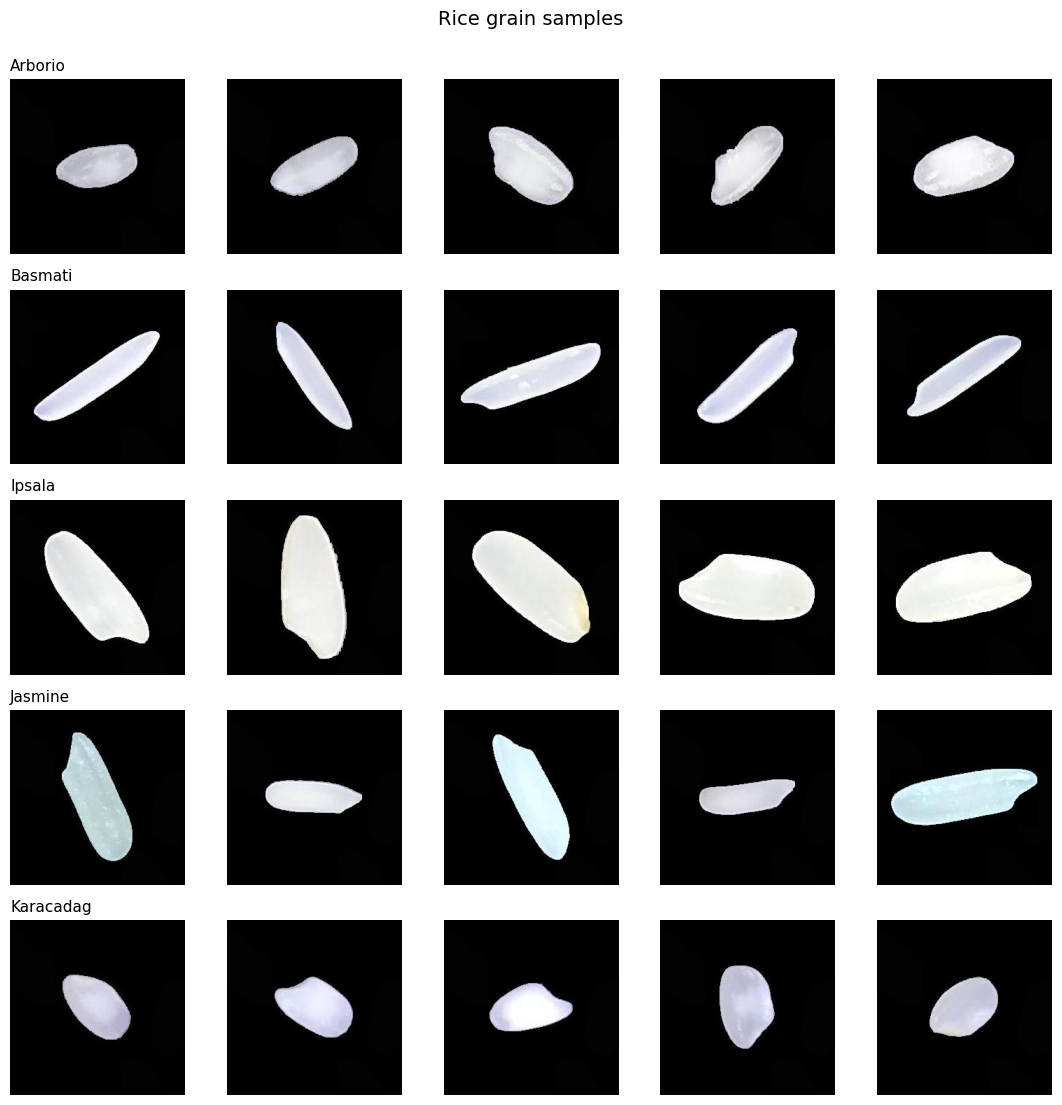

In [4]:
# a few raw samples from the TEST split (the same images are used later to compare predictions)
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(11, 2.2 * NUM_CLASSES))
for c, cls in enumerate(CLASS_NAMES):
    idx = np.where(SPLITS["test"][1] == c)[0][:5]
    for ax, i in zip(axes[c], idx):
        ax.imshow(Image.open(SPLITS["test"][0][i]).convert("RGB")); ax.axis("off")
    axes[c][0].set_title(cls, loc="left", fontsize=11)
plt.suptitle("Rice grain samples", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

### 0.3 Shared evaluation toolkit

Both frameworks only have to produce **`y_true`, `y_prob` (softmax probabilities) and a `history`**. All metrics and plots below are computed from those arrays by the same code, so the numbers are directly comparable.

| Metric / plot | Where |
|---|---|
| Train vs validation loss and accuracy | `plot_history` |
| Classification report (precision / recall / F1 per class) | `report` |
| Confusion matrix (counts and row-normalised) | `plot_confusion` |
| ROC curves + AUC (one-vs-rest per class, micro, macro) | `plot_roc` |
| Precision-recall curves + average precision | `plot_pr` |
| Example predictions and most confident mistakes | `show_predictions` |

In [5]:
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, average_precision_score,
                             precision_recall_fscore_support, log_loss)
from sklearn.preprocessing import label_binarize

FW_COLORS = {"TensorFlow": "tab:orange", "PyTorch": "tab:blue"}
RESULTS = {}

# ----------------------------------------------------------------- storage
def register_result(framework, model_name, history, y_true, y_prob, n_params, train_time, best_epoch,
                    val_true=None, val_prob=None):
    """Store one trained model's outputs (in memory and on disk)."""
    key = f"{framework.lower()}_{model_name.lower().replace(' ', '')}"
    res = dict(key=key, framework=framework, model=model_name,
               history={k: [float(v) for v in history[k]] for k in ("loss", "accuracy", "val_loss", "val_accuracy")},
               y_true=np.asarray(y_true).astype(int), y_prob=np.asarray(y_prob, dtype=np.float64),
               n_params=int(n_params), train_time=float(train_time), best_epoch=int(best_epoch),
               val_true=None if val_true is None else np.asarray(val_true).astype(int),
               val_prob=None if val_prob is None else np.asarray(val_prob, dtype=np.float64), seed=SEED)
    RESULTS[key] = res
    with open(OUT_DIR / "results" / f"{key}.pkl", "wb") as f:
        pickle.dump(res, f)
    return res

def load_saved_results():
    for p in sorted((OUT_DIR / "results").glob("*.pkl")):
        with open(p, "rb") as f:
            res = pickle.load(f)
        RESULTS[res["key"]] = res
    return RESULTS

# ----------------------------------------------------------------- curve data
def roc_data(y_true, y_prob):
    Y = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    out = {}
    for c, name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Y[:, c], y_prob[:, c])
        out[name] = (fpr, tpr, auc(fpr, tpr))
    fpr, tpr, _ = roc_curve(Y.ravel(), y_prob.ravel())
    out["micro"] = (fpr, tpr, auc(fpr, tpr))
    grid = np.unique(np.concatenate([out[n][0] for n in CLASS_NAMES]))
    mean_tpr = np.mean([np.interp(grid, out[n][0], out[n][1]) for n in CLASS_NAMES], axis=0)
    out["macro"] = (grid, mean_tpr, auc(grid, mean_tpr))
    return out

def pr_data(y_true, y_prob):
    Y = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    out = {}
    for c, name in enumerate(CLASS_NAMES):
        p, r, _ = precision_recall_curve(Y[:, c], y_prob[:, c])
        out[name] = (r, p, average_precision_score(Y[:, c], y_prob[:, c]))
    p, r, _ = precision_recall_curve(Y.ravel(), y_prob.ravel())
    out["micro"] = (r, p, average_precision_score(Y.ravel(), y_prob.ravel()))
    out["macro"] = (None, None, float(np.mean([out[n][2] for n in CLASS_NAMES])))
    return out

def summarize(res):
    """One row of headline numbers for a model."""
    yt, yp = res["y_true"], res["y_prob"]
    pred = yp.argmax(1)
    prec, rec, f1, _ = precision_recall_fscore_support(yt, pred, average="macro", zero_division=0)
    roc, pr = roc_data(yt, yp), pr_data(yt, yp)
    h, b = res["history"], res["best_epoch"] - 1
    n_ep = len(h["loss"])
    val_ce = (log_loss(res["val_true"], res["val_prob"], labels=list(range(NUM_CLASSES)))
              if res.get("val_prob") is not None else float("nan"))
    return {"Params": res["n_params"], "Epochs run": n_ep, "Best epoch": res["best_epoch"],
            "Train time (s)": res["train_time"], "Sec/epoch": res["train_time"] / n_ep,
            "Train acc": h["accuracy"][b], "Val acc": h["val_accuracy"][b], "Val CE": val_ce,
            "Test acc": accuracy_score(yt, pred),
            "Test CE": log_loss(yt, yp, labels=list(range(NUM_CLASSES))),
            "Precision (macro)": prec, "Recall (macro)": rec, "F1 (macro)": f1,
            "ROC-AUC (macro)": roc["macro"][2], "ROC-AUC (micro)": roc["micro"][2],
            "Avg precision (macro)": pr["macro"][2], "Avg precision (micro)": pr["micro"][2]}

# ----------------------------------------------------------------- plots
def plot_history(res, axes=None):
    h, b = res["history"], res["best_epoch"]
    own = axes is None
    if own:
        _, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    ep = np.arange(1, len(h["loss"]) + 1)
    for ax, tr, va, title, ylab in [(axes[0], "loss", "val_loss", "Loss", "Loss"),
                                    (axes[1], "accuracy", "val_accuracy", "Accuracy", "Accuracy")]:
        ax.plot(ep, h[tr], "o-", color="tab:red", label="Train")
        ax.plot(ep, h[va], "h-", color="tab:blue", label="Validation")
        ax.axvline(b, color="gray", ls=":", label=f"Best epoch ({b})")
        ax.set_title(f"{res['framework']} · {res['model']} · {title}")
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylab); ax.grid(alpha=.3); ax.legend()
    if own:
        plt.tight_layout(); plt.show()

def plot_confusion(res, axes=None):
    own = axes is None
    if own:
        _, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    pred = res["y_prob"].argmax(1)
    ConfusionMatrixDisplay.from_predictions(res["y_true"], pred, display_labels=CLASS_NAMES, ax=axes[0],
                                            cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d")
    axes[0].set_title(f"{res['framework']} · {res['model']} · counts")
    ConfusionMatrixDisplay.from_predictions(res["y_true"], pred, display_labels=CLASS_NAMES, ax=axes[1],
                                            cmap="Blues", colorbar=False, xticks_rotation=45,
                                            normalize="true", values_format=".1%")
    axes[1].set_title(f"{res['framework']} · {res['model']} · row-normalised (recall)")
    for ax in axes:
        ax.grid(False)
    if own:
        plt.tight_layout(); plt.show()

def _draw_roc(ax, data, zoom):
    for name in CLASS_NAMES:
        fpr, tpr, a = data[name]
        ax.plot(fpr, tpr, lw=1.6, label=f"{name} (AUC={a:.4f})")
    ax.plot(*data["micro"][:2], "k--", lw=1.2, label=f"micro-avg (AUC={data['micro'][2]:.4f})")
    ax.plot(*data["macro"][:2], "k:", lw=1.6, label=f"macro-avg (AUC={data['macro'][2]:.4f})")
    if zoom:
        ax.set_xlim(-0.002, 0.05); ax.set_ylim(0.95, 1.003)
    else:
        ax.plot([0, 1], [0, 1], color="lightgray", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.grid(alpha=.3)

def plot_roc(res):
    data = roc_data(res["y_true"], res["y_prob"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    _draw_roc(axes[0], data, zoom=False); axes[0].legend(loc="lower right", fontsize=8)
    axes[0].set_title(f"{res['framework']} · {res['model']} · ROC (one-vs-rest)")
    _draw_roc(axes[1], data, zoom=True)
    axes[1].set_title("Zoom on the top-left corner")
    plt.tight_layout(); plt.show()

def _draw_pr(ax, data, zoom):
    for name in CLASS_NAMES:
        r, p, a = data[name]
        ax.plot(r, p, lw=1.6, label=f"{name} (AP={a:.4f})")
    ax.plot(*data["micro"][:2], "k--", lw=1.2, label=f"micro-avg (AP={data['micro'][2]:.4f})")
    if zoom:
        ax.set_xlim(0.9, 1.003); ax.set_ylim(0.9, 1.003)
    else:
        ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.03)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.grid(alpha=.3)

def plot_pr(res):
    data = pr_data(res["y_true"], res["y_prob"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    _draw_pr(axes[0], data, zoom=False); axes[0].legend(loc="lower left", fontsize=8)
    axes[0].set_title(f"{res['framework']} · {res['model']} · Precision-Recall")
    _draw_pr(axes[1], data, zoom=True)
    axes[1].set_title("Zoom on the top-right corner")
    plt.tight_layout(); plt.show()

def report(res):
    """Full evaluation of one trained model on the TEST set."""
    yt, pred = res["y_true"], res["y_prob"].argmax(1)
    s = summarize(res)
    print(f"{res['framework']} · {res['model']}   |   params: {s['Params']:,}   epochs run: {s['Epochs run']} "
          f"(best: {s['Best epoch']})   train time: {s['Train time (s)']:.0f}s")
    print(f"TEST  accuracy: {s['Test acc']:.4f}   cross-entropy: {s['Test CE']:.4f}   "
          f"macro ROC-AUC: {s['ROC-AUC (macro)']:.4f}   macro avg-precision: {s['Avg precision (macro)']:.4f}\n")
    plot_history(res)
    print(classification_report(yt, pred, target_names=CLASS_NAMES, digits=4))
    plot_confusion(res)
    plot_roc(res)
    plot_pr(res)

def show_predictions(res, n=12, only_errors=False, seed=0):
    """Image grid with predicted class, confidence and true class (green = correct, red = wrong)."""
    yt, yp = res["y_true"], res["y_prob"]
    pred, conf = yp.argmax(1), yp.max(1)
    if only_errors:
        idx = np.where(pred != yt)[0]
        idx = idx[np.argsort(-conf[idx])][:n]          # most confident mistakes first
        title = f"{res['framework']} · {res['model']} · most confident mistakes"
    else:
        idx = np.random.default_rng(seed).choice(len(yt), size=n, replace=False)   # same images for every model
        title = f"{res['framework']} · {res['model']} · random test images"
    if len(idx) == 0:
        print("No misclassified test images."); return
    cols = 4; rows = math.ceil(len(idx) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.1 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(Image.open(SPLITS["test"][0][i]).convert("RGB"))
        ok = pred[i] == yt[i]
        ax.set_title(f"{CLASS_NAMES[pred[i]]} {conf[i]:.0%}\n(true: {CLASS_NAMES[yt[i]]})",
                     fontsize=9, color="green" if ok else "red")
    plt.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()

<a class="anchor" id="sec1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">1 · CNN with TensorFlow / Keras</p>

### 1.1 Setup and input pipeline

In [6]:
import tensorflow as tf
from tensorflow import keras

# Let TensorFlow grow its GPU memory on demand instead of reserving all of it (important on Kaggle,
# where PyTorch will use the same GPU later in this notebook).
try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
except RuntimeError as e:
    print("GPU memory growth could not be set:", e)

print("TensorFlow", tf.__version__, "| GPUs visible:", tf.config.list_physical_devices("GPU"))
AUTOTUNE = tf.data.AUTOTUNE

def load_image_tf(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)      # float32 in [0, 255]
    return img, label

def make_tf_dataset(split, shuffle=False):
    paths, labels = SPLITS[split]
    ds = tf.data.Dataset.from_tensor_slices((np.array(paths), labels.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image_tf, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

tf_train = make_tf_dataset("train", shuffle=True)
tf_val   = make_tf_dataset("val")
tf_test  = make_tf_dataset("test")        # not shuffled: predictions line up with SPLITS["test"]

for name, ds in [("Train", tf_train), ("Validation", tf_val), ("Test", tf_test)]:
    x, y = next(iter(ds))
    print(f"{name:<11} batches: {len(ds):>4} | X: {x.shape} {x.dtype.name} | y: {y.shape} {y.dtype.name}")

TensorFlow 2.17.1 | GPUs visible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Train       batches: 1641 | X: (32, 150, 150, 3) float32 | y: (32,) int32
Validation  batches:  352 | X: (32, 150, 150, 3) float32 | y: (32,) int32
Test        batches:  352 | X: (32, 150, 150, 3) float32 | y: (32,) int32


In [7]:
def set_seed_tf():
    keras.utils.set_random_seed(SEED)       # python, numpy and tensorflow seeds

class RestoreBestWeights(keras.callbacks.Callback):
    """Keep the weights of the epoch with the lowest val_loss and restore them when training ends."""
    def on_train_begin(self, logs=None):
        self.best, self.best_weights, self.best_epoch = np.inf, None, 0
    def on_epoch_end(self, epoch, logs=None):
        if logs["val_loss"] < self.best:
            self.best, self.best_epoch = logs["val_loss"], epoch + 1
            self.best_weights = self.model.get_weights()
    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)

def build_tf_model(regularized, name):
    reg = keras.regularizers.l2(L2_FACTOR) if regularized else None
    layers = [
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        keras.layers.Rescaling(1.0 / 255),
        keras.layers.Conv2D(32, 3, activation="relu", kernel_regularizer=reg),
        keras.layers.MaxPool2D(pool_size=2, strides=2),
        keras.layers.Flatten(),
        keras.layers.Dense(300, activation="relu", kernel_regularizer=reg),
    ]
    if regularized:
        layers += [keras.layers.Dense(100, activation="relu", kernel_regularizer=reg),
                   keras.layers.Dropout(DROPOUT_RATE)]
    layers.append(keras.layers.Dense(NUM_CLASSES))          # logits
    return keras.Sequential(layers, name=name)

def train_tf(model, model_name):
    """Compile, fit with early stopping, predict on the test set and store the result."""
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    best = RestoreBestWeights()
    print("Keras jit_compile (XLA) resolved to:", getattr(model, "jit_compile", "n/a"))
    t0 = time.perf_counter()
    hist = model.fit(tf_train, validation_data=tf_val, epochs=MAX_EPOCHS, verbose=2,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE), best])
    train_time = time.perf_counter() - t0
    y_prob = tf.nn.softmax(model.predict(tf_test, verbose=0), axis=1).numpy()
    val_prob = tf.nn.softmax(model.predict(tf_val, verbose=0), axis=1).numpy()
    return register_result("TensorFlow", model_name, hist.history, SPLITS["test"][1], y_prob,
                           model.count_params(), train_time, best.best_epoch,
                           val_true=SPLITS["val"][1], val_prob=val_prob)

TF_MODELS = {}

### 1.2 Model 1: baseline

`Rescaling → Conv2D(32, 3×3) → MaxPool(2×2) → Flatten → Dense(300) → Dense(5)`; ReLU activations, Adam, no regularisation.

In [8]:
set_seed_tf()
tf_model_1 = build_tf_model(regularized=False, name="tf_model_1")
tf_model_1.summary()

Model: "tf_model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 175232)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 300)                 │      52,569,900 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           1,505 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,572,301 (200.55 MB)

 Trainable params: 52,572,301 (200.55 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
res_tf1 = train_tf(tf_model_1, "Model 1")
TF_MODELS[res_tf1["key"]] = tf_model_1

Keras jit_compile (XLA) resolved to: True
Epoch 1/20
1641/1641 - 60s - 36ms/step - accuracy: 0.9711 - loss: 0.0898 - val_accuracy: 0.9484 - val_loss: 0.1853
Epoch 2/20
1641/1641 - 52s - 32ms/step - accuracy: 0.9883 - loss: 0.0366 - val_accuracy: 0.9852 - val_loss: 0.0504
Epoch 3/20
1641/1641 - 51s - 31ms/step - accuracy: 0.9912 - loss: 0.0258 - val_accuracy: 0.9912 - val_loss: 0.0269
Epoch 4/20
1641/1641 - 51s - 31ms/step - accuracy: 0.9894 - loss: 0.0308 - val_accuracy: 0.9851 - val_loss: 0.0465
Epoch 5/20
1641/1641 - 51s - 31ms/step - accuracy: 0.9932 - loss: 0.0193 - val_accuracy: 0.9865 - val_loss: 0.0493
Epoch 6/20
1641/1641 - 82s - 50ms/step - accuracy: 0.9882 - loss: 0.0326 - val_accuracy: 0.9747 - val_loss: 0.0898
Epoch 7/20
1641/1641 - 52s - 31ms/step - accuracy: 0.9878 - loss: 0.0333 - val_accuracy: 0.9716 - val_loss: 0.1063
Epoch 8/20
1641/1641 - 52s - 32ms/step - accuracy: 0.9937 - loss: 0.0177 - val_accuracy: 0.9770 - val_loss: 0.0967


TensorFlow · Model 1   |   params: 52,572,301   epochs run: 8 (best: 3)   train time: 451s
TEST  accuracy: 0.9926   cross-entropy: 0.0246   macro ROC-AUC: 0.9998   macro avg-precision: 0.9989



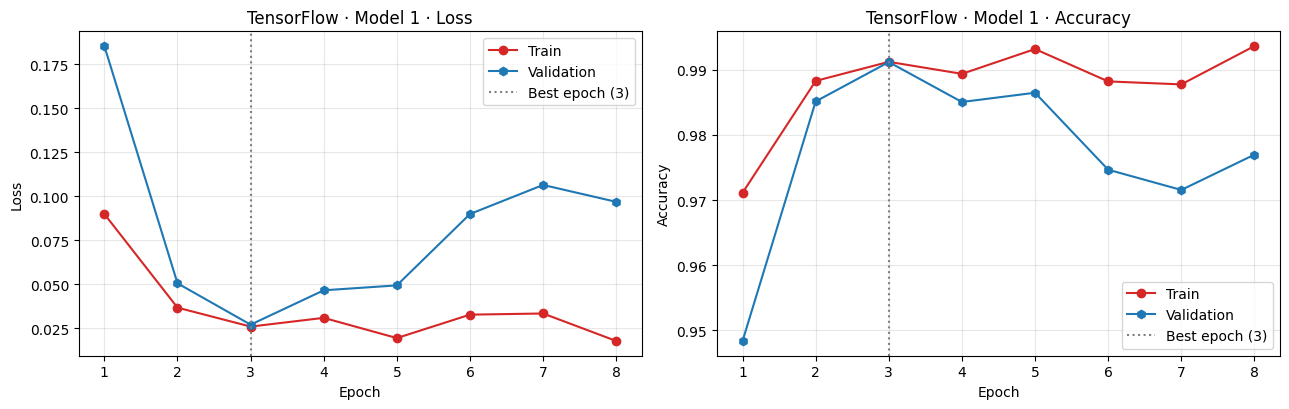

              precision    recall  f1-score   support

     Arborio     0.9837    0.9938    0.9887      2250
     Basmati     0.9929    0.9929    0.9929      2250
      Ipsala     0.9996    0.9991    0.9993      2250
     Jasmine     0.9906    0.9871    0.9889      2250
   Karacadag     0.9964    0.9902    0.9933      2250

    accuracy                         0.9926     11250
   macro avg     0.9926    0.9926    0.9926     11250
weighted avg     0.9926    0.9926    0.9926     11250



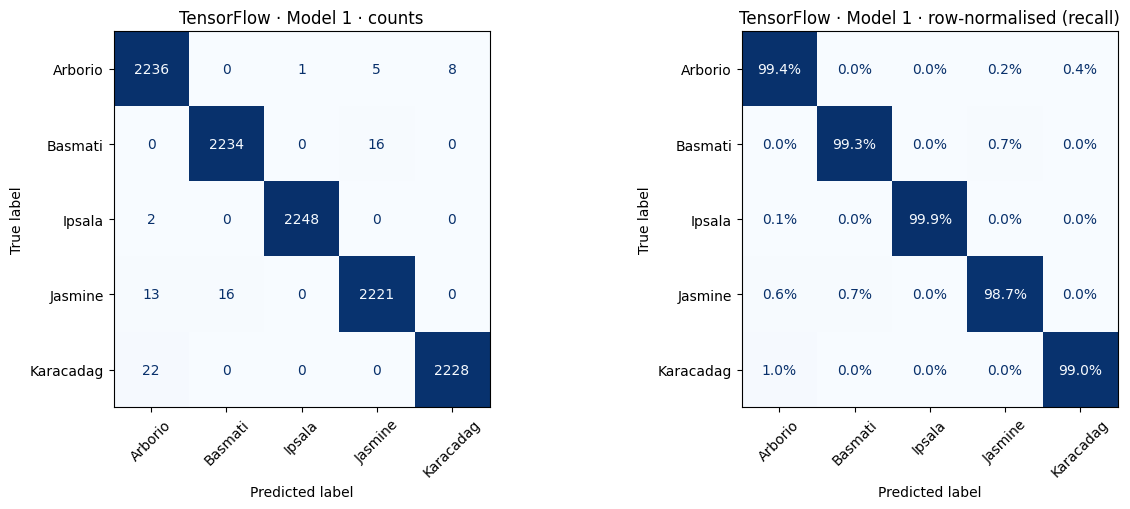

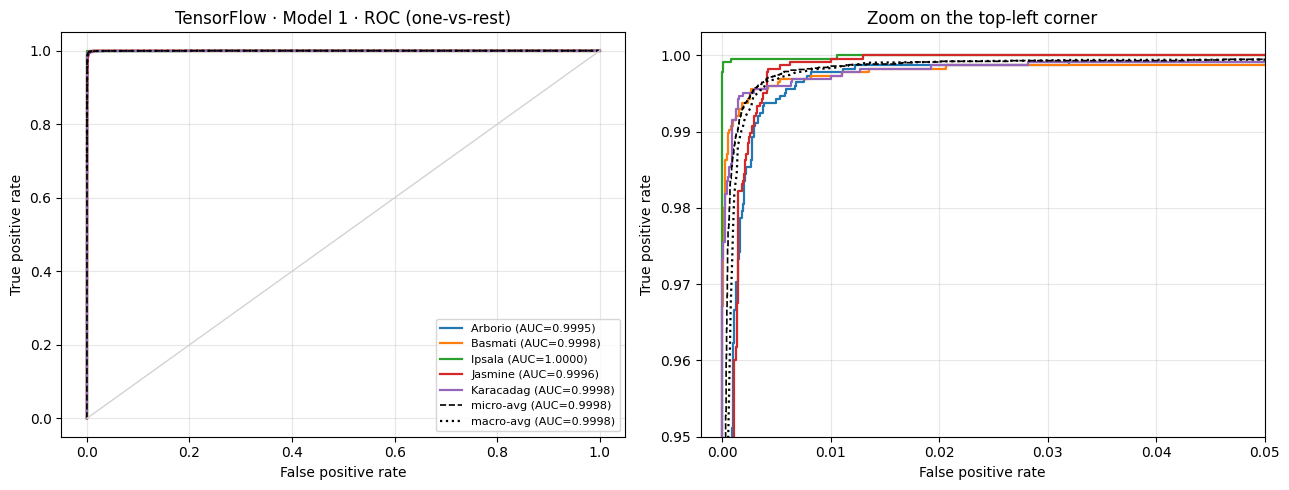

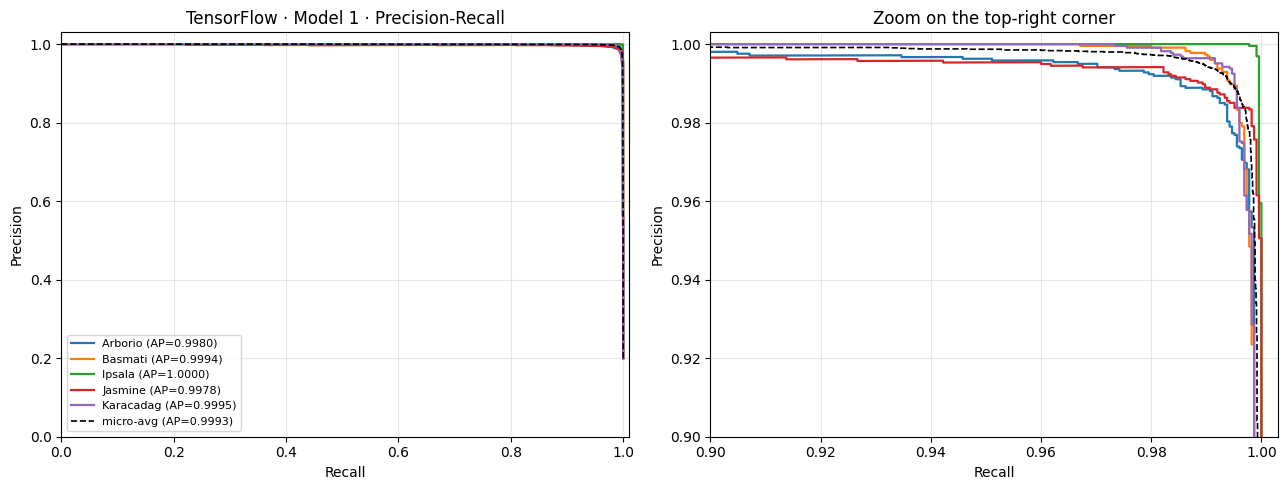

In [10]:
report(res_tf1)

### 1.3 Model 2: regularised

Same architecture as Model 1, plus **L2 regularisation** on the conv and hidden dense kernels, an **extra Dense(100)** layer and **Dropout(0.5)**, to reduce the over-fitting gap seen in Model 1.

In [11]:
set_seed_tf()
tf_model_2 = build_tf_model(regularized=True, name="tf_model_2")
tf_model_2.summary()

Model: "tf_model_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 175232)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 300)                 │      52,569,900 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 100)                 │          30,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 5)                   │             505 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 52,601,401 (200.66 MB)

 Trainable params: 52,601,401 (200.66 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
res_tf2 = train_tf(tf_model_2, "Model 2")
TF_MODELS[res_tf2["key"]] = tf_model_2

Keras jit_compile (XLA) resolved to: True
Epoch 1/20
1641/1641 - 61s - 37ms/step - accuracy: 0.9366 - loss: 0.3977 - val_accuracy: 0.9710 - val_loss: 0.2221
Epoch 2/20
1641/1641 - 53s - 32ms/step - accuracy: 0.9659 - loss: 0.2040 - val_accuracy: 0.9792 - val_loss: 0.1329
Epoch 3/20
1641/1641 - 52s - 32ms/step - accuracy: 0.9743 - loss: 0.1480 - val_accuracy: 0.9764 - val_loss: 0.1247
Epoch 4/20
1641/1641 - 52s - 32ms/step - accuracy: 0.9694 - loss: 0.1535 - val_accuracy: 0.9752 - val_loss: 0.1250
Epoch 5/20
1641/1641 - 53s - 32ms/step - accuracy: 0.9785 - loss: 0.1203 - val_accuracy: 0.9855 - val_loss: 0.0938
Epoch 6/20
1641/1641 - 54s - 33ms/step - accuracy: 0.9788 - loss: 0.1145 - val_accuracy: 0.9838 - val_loss: 0.0963
Epoch 7/20
1641/1641 - 52s - 31ms/step - accuracy: 0.9814 - loss: 0.1071 - val_accuracy: 0.9768 - val_loss: 0.1118
Epoch 8/20
1641/1641 - 52s - 32ms/step - accuracy: 0.9821 - loss: 0.1004 - val_accuracy: 0.9862 - val_loss: 0.0848
Epoch 9/20
1641/1641 - 52s - 32ms/step

TensorFlow · Model 2   |   params: 52,601,401   epochs run: 17 (best: 12)   train time: 895s
TEST  accuracy: 0.9882   cross-entropy: 0.0354   macro ROC-AUC: 0.9997   macro avg-precision: 0.9986



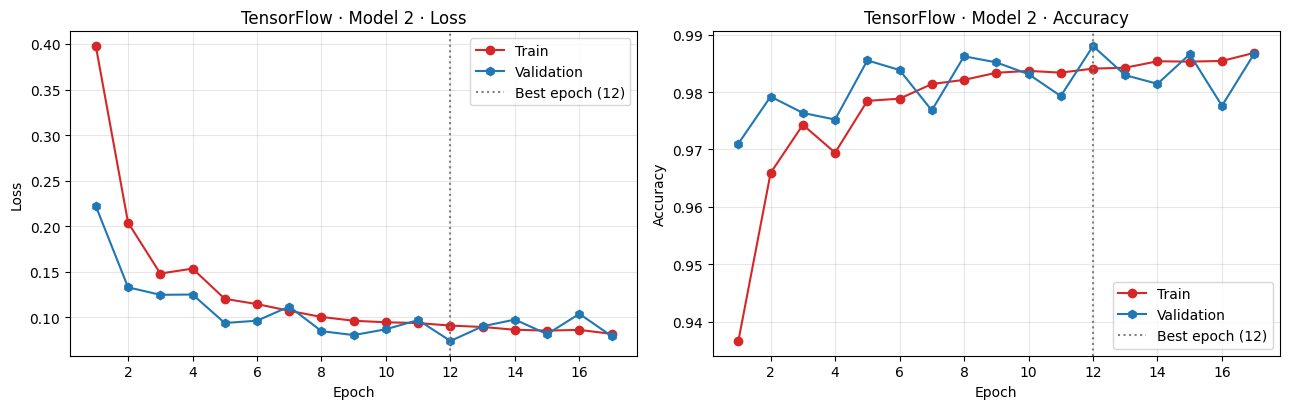

              precision    recall  f1-score   support

     Arborio     0.9837    0.9933    0.9885      2250
     Basmati     0.9932    0.9751    0.9841      2250
      Ipsala     0.9982    0.9960    0.9971      2250
     Jasmine     0.9679    0.9907    0.9791      2250
   Karacadag     0.9986    0.9858    0.9922      2250

    accuracy                         0.9882     11250
   macro avg     0.9883    0.9882    0.9882     11250
weighted avg     0.9883    0.9882    0.9882     11250



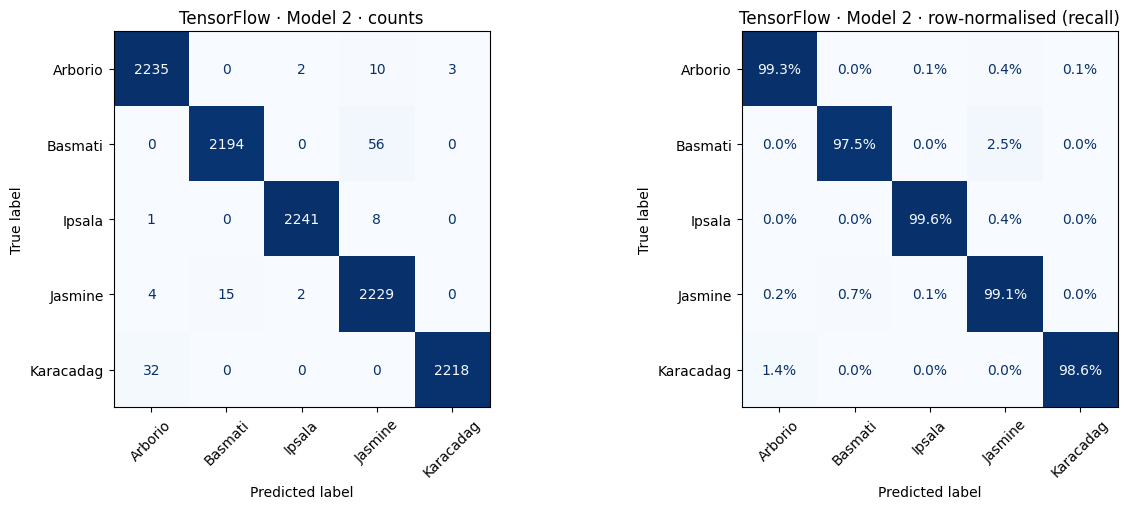

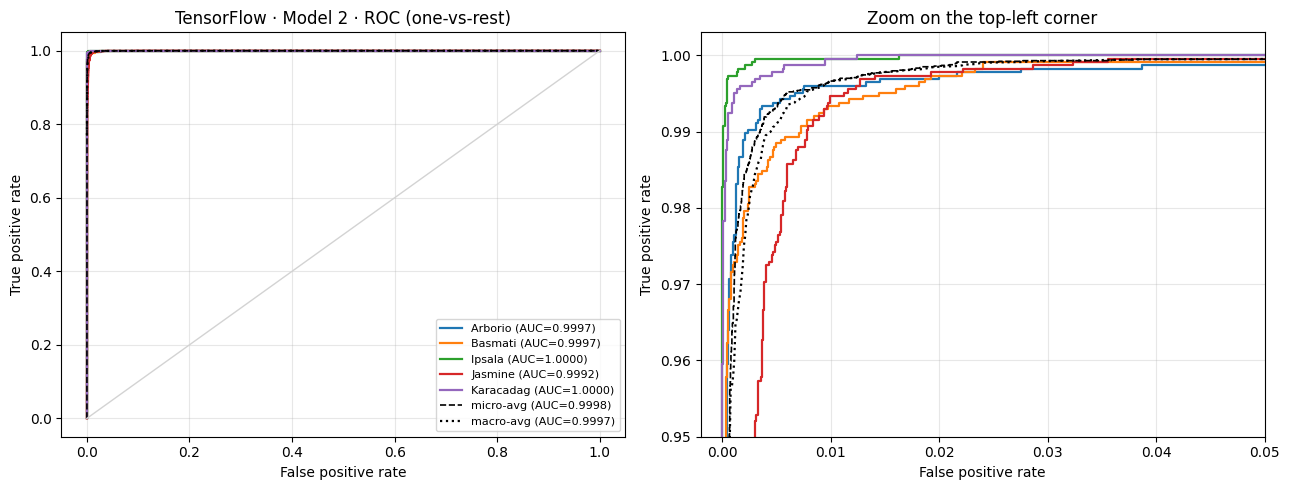

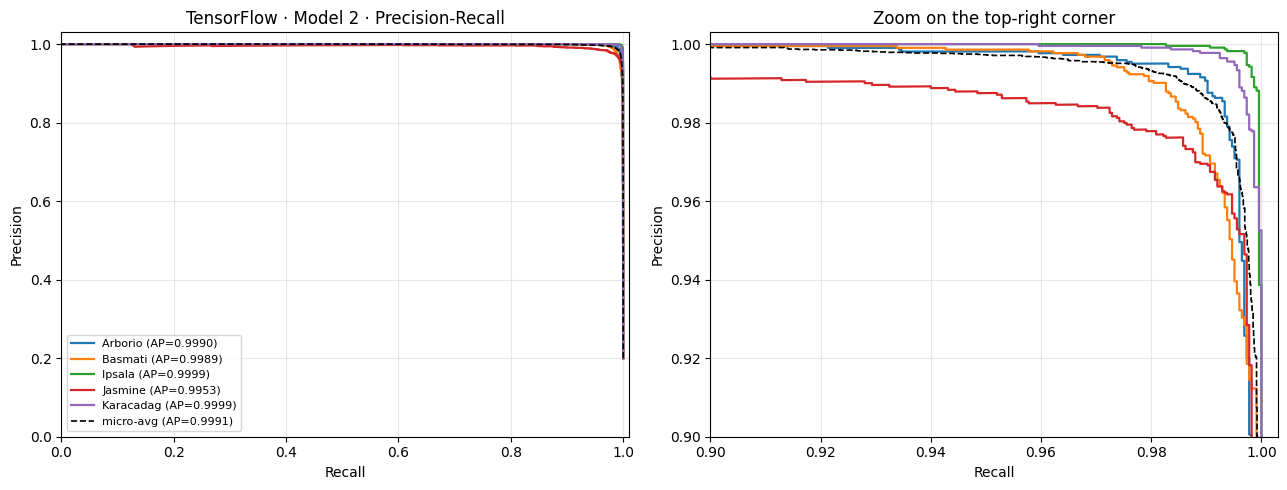

In [13]:
report(res_tf2)

### 1.4 Final TensorFlow model

The final model is chosen on the **validation cross-entropy** (never on the test set). The loss reported during training cannot be used for this: for Model 2 it includes the L2 penalty, so it is always higher than Model 1's and the two would not be comparable.

Selected: TensorFlow · Model 1   (lowest validation cross-entropy: 0.0269)


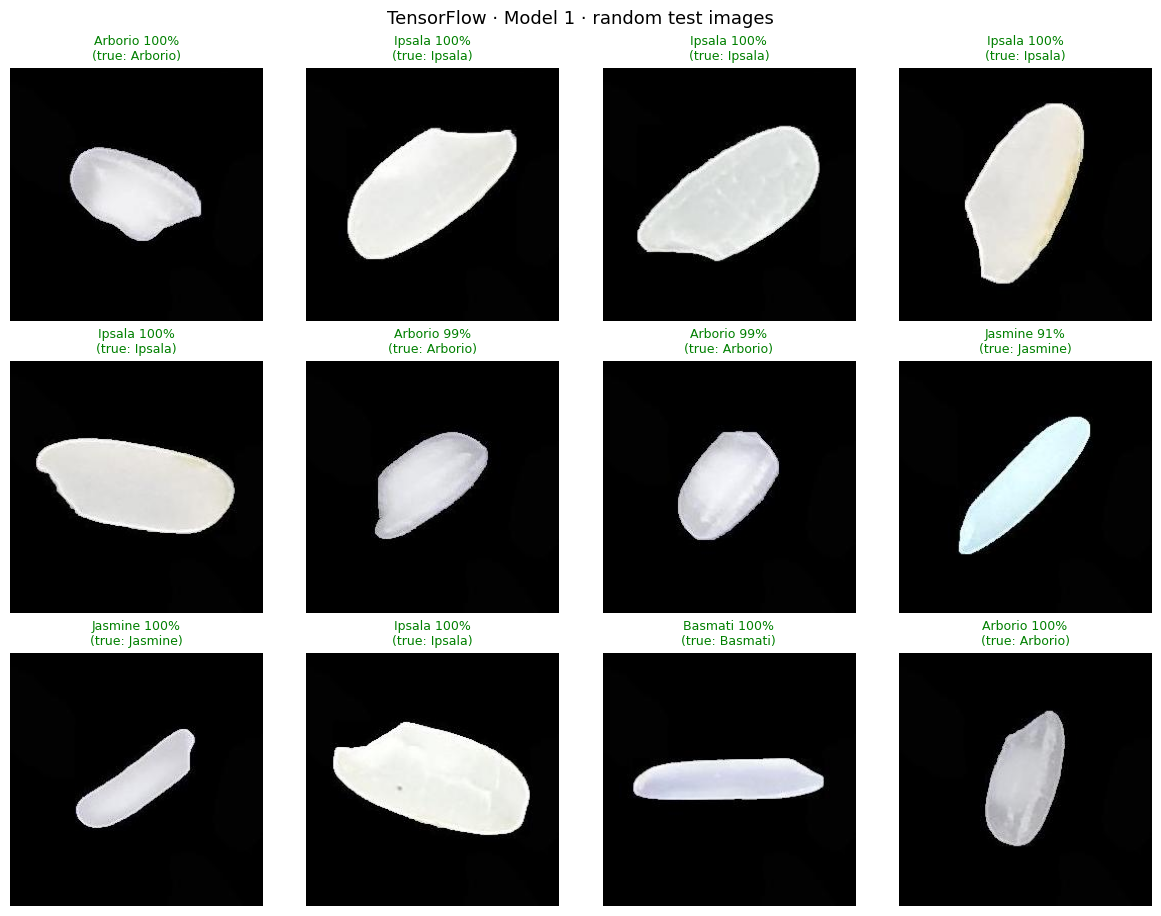

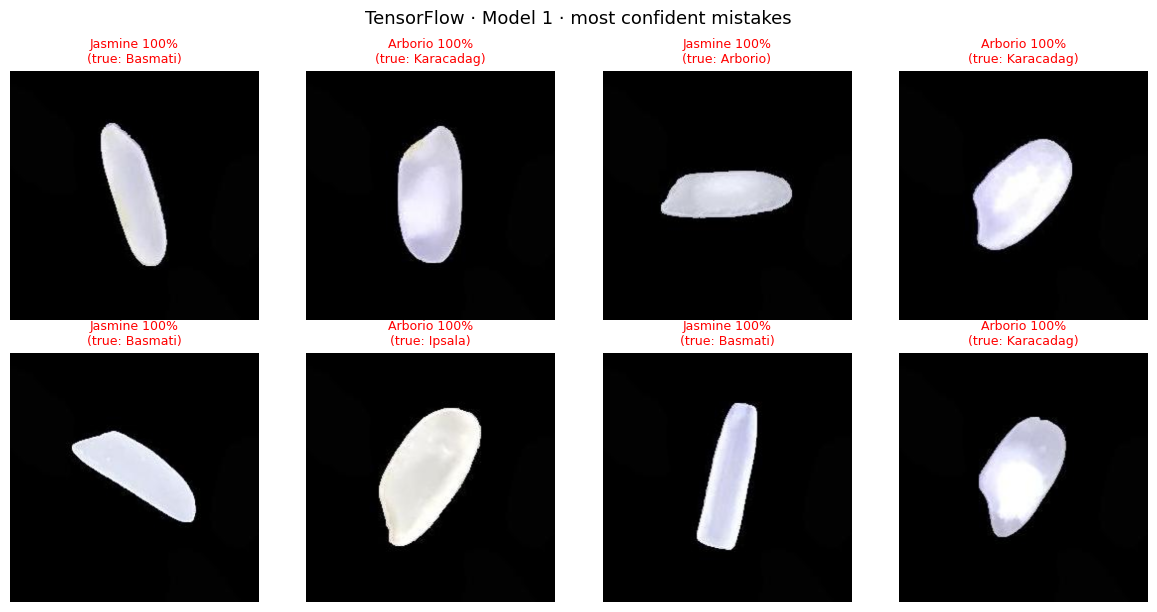

In [14]:
tf_candidates = {k: v for k, v in RESULTS.items() if v["framework"] == "TensorFlow"}
def val_cross_entropy(r):
    return log_loss(r["val_true"], r["val_prob"], labels=list(range(NUM_CLASSES)))

tf_final_key = min(tf_candidates, key=lambda k: val_cross_entropy(tf_candidates[k]))
tf_final = RESULTS[tf_final_key]
print(f"Selected: TensorFlow · {tf_final['model']}   (lowest validation cross-entropy: {val_cross_entropy(tf_final):.4f})")

if tf_final_key in TF_MODELS:
    TF_MODELS[tf_final_key].save(OUT_DIR / "tensorflow_final_model.keras")

show_predictions(tf_final, n=12)
show_predictions(tf_final, n=8, only_errors=True)

<a class="anchor" id="sec2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">2 · CNN with PyTorch</p>

### 2.1 Setup and input pipeline

PyTorch models below are written to be **architecturally identical** to the Keras ones (same layers, widths, Glorot initialisation, Adam epsilon, L2 formula, dropout, early stopping). The only intended difference is the framework.

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU")

# Windows notebooks cannot use worker processes for classes defined inside the notebook
NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)

# Resize + ToTensor gives float32 in [0, 1], the same range as Keras' Rescaling(1/255)
pt_transform = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])

class RiceDataset(torch.utils.data.Dataset):
    def __init__(self, split):
        self.paths, self.labels = SPLITS[split]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return pt_transform(Image.open(self.paths[i]).convert("RGB")), int(self.labels[i])

def make_loader(split, shuffle=False):
    g = torch.Generator().manual_seed(SEED)
    return torch.utils.data.DataLoader(RiceDataset(split), batch_size=BATCH_SIZE, shuffle=shuffle,
                                       num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                                       persistent_workers=NUM_WORKERS > 0, generator=g)

pt_train, pt_val, pt_test = make_loader("train", True), make_loader("val"), make_loader("test")

for name, dl in [("Train", pt_train), ("Validation", pt_val), ("Test", pt_test)]:
    x, y = next(iter(dl))
    print(f"{name:<11} batches: {len(dl):>4} | X [N,C,H,W]: {tuple(x.shape)} {x.dtype} | y: {tuple(y.shape)} {y.dtype}")

PyTorch 2.5.1+cu121 | device: cuda | Tesla T4
Train       batches: 1641 | X [N,C,H,W]: (32, 3, 150, 150) torch.float32 | y: (32,) torch.int64
Validation  batches:  352 | X [N,C,H,W]: (32, 3, 150, 150) torch.float32 | y: (32,) torch.int64
Test        batches:  352 | X [N,C,H,W]: (32, 3, 150, 150) torch.float32 | y: (32,) torch.int64


In [16]:
def set_seed_torch():
    random.seed(SEED); np.random.seed(SEED)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

def keras_style_init(m):
    """Keras defaults: Glorot-uniform weights, zero biases (PyTorch defaults differ)."""
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

class RiceCNN(nn.Module):
    """Model 1 (regularized=False) and Model 2 (regularized=True): mirrors the Keras models."""
    def __init__(self, regularized):
        super().__init__()
        self.regularized = regularized
        flat = 32 * ((IMG_SIZE - 2) // 2) ** 2              # conv 3x3 (no padding) then 2x2 max-pool
        self.features = nn.Sequential(nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Flatten())
        if regularized:
            self.classifier = nn.Sequential(
                nn.Linear(flat, 300), nn.ReLU(),
                nn.Linear(300, 100), nn.ReLU(),
                nn.Dropout(DROPOUT_RATE),
                nn.Linear(100, NUM_CLASSES))
            self._l2_layers = [self.features[0], self.classifier[0], self.classifier[2]]
        else:
            self.classifier = nn.Sequential(nn.Linear(flat, 300), nn.ReLU(), nn.Linear(300, NUM_CLASSES))
            self._l2_layers = []
        self.apply(keras_style_init)

    def forward(self, x):
        return self.classifier(self.features(x))

    def reg_loss(self):
        """Same as Keras kernel_regularizer=l2(L2_FACTOR): L2_FACTOR * sum(w^2); the output layer is not penalised."""
        if not self._l2_layers:
            return 0.0
        return L2_FACTOR * sum((m.weight ** 2).sum() for m in self._l2_layers)

def run_epoch_eval(model, loader, ce):
    """Loss (incl. L2 term, like Keras) and accuracy on a loader."""
    model.eval()
    loss_sum, correct, seen = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            out = model(x)
            loss_sum += (ce(out, y) + model.reg_loss()).item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            seen += y.size(0)
    return loss_sum / seen, correct / seen

def predict_proba_torch(model, loader):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(torch.softmax(model(x.to(DEVICE, non_blocking=True)), dim=1).cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(labels), np.concatenate(probs)

def train_torch(model, model_name):
    """Train with Adam + early stopping on val loss (best weights restored), then predict on the test set."""
    model.to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=1e-7)   # eps = Keras default
    ce = nn.CrossEntropyLoss()
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, correct, seen = 0.0, 0, 0
        for x, y in tqdm(pt_train, desc=f"Epoch {epoch}/{MAX_EPOCHS}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            out = model(x)
            loss = ce(out, y) + model.reg_loss()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            seen += y.size(0)
        val_loss, val_acc = run_epoch_eval(model, pt_val, ce)
        for k, v in zip(history, (loss_sum / seen, correct / seen, val_loss, val_acc)):
            history[k].append(v)
        print(f"Epoch {epoch:>2}/{MAX_EPOCHS} - loss: {history['loss'][-1]:.4f} - acc: {history['accuracy'][-1]:.4f}"
              f" - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

        if val_loss < best_val:
            best_val, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Early stopping at epoch {epoch}; restoring weights from epoch {best_epoch}.")
                break

    train_time = time.perf_counter() - t0
    model.load_state_dict(best_state)
    y_true, y_prob = predict_proba_torch(model, pt_test)
    val_true, val_prob = predict_proba_torch(model, pt_val)
    n_params = sum(p.numel() for p in model.parameters())
    return register_result("PyTorch", model_name, history, y_true, y_prob, n_params, train_time, best_epoch,
                           val_true=val_true, val_prob=val_prob)

PT_MODELS = {}

### 2.2 Model 1: baseline

`Conv2d(3→32, 3×3) → ReLU → MaxPool(2×2) → Flatten → Linear(300) → ReLU → Linear(5)`; Adam, no regularisation.

In [17]:
set_seed_torch()
pt_model_1 = RiceCNN(regularized=False)
print(pt_model_1)
print(f"\nTrainable parameters: {sum(p.numel() for p in pt_model_1.parameters() if p.requires_grad):,}")

RiceCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=175232, out_features=300, bias=True)
    (1): ReLU()
    (2): Linear(in_features=300, out_features=5, bias=True)
  )
)

Trainable parameters: 52,572,301


In [18]:
res_pt1 = train_torch(pt_model_1, "Model 1")
PT_MODELS[res_pt1["key"]] = pt_model_1

Epoch 1/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  1/20 - loss: 0.1340 - acc: 0.9620 - val_loss: 0.0653 - val_acc: 0.9772


Epoch 2/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  2/20 - loss: 0.0407 - acc: 0.9865 - val_loss: 0.0658 - val_acc: 0.9781


Epoch 3/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  3/20 - loss: 0.0310 - acc: 0.9892 - val_loss: 0.1076 - val_acc: 0.9651


... (8 outputs left out)

Epoch 8/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  8/20 - loss: 0.0085 - acc: 0.9972 - val_loss: 0.0763 - val_acc: 0.9831


Epoch 9/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  9/20 - loss: 0.0070 - acc: 0.9978 - val_loss: 0.0667 - val_acc: 0.9855
Early stopping at epoch 9; restoring weights from epoch 4.


PyTorch · Model 1   |   params: 52,572,301   epochs run: 9 (best: 4)   train time: 690s
TEST  accuracy: 0.9876   cross-entropy: 0.0398   macro ROC-AUC: 0.9998   macro avg-precision: 0.9990



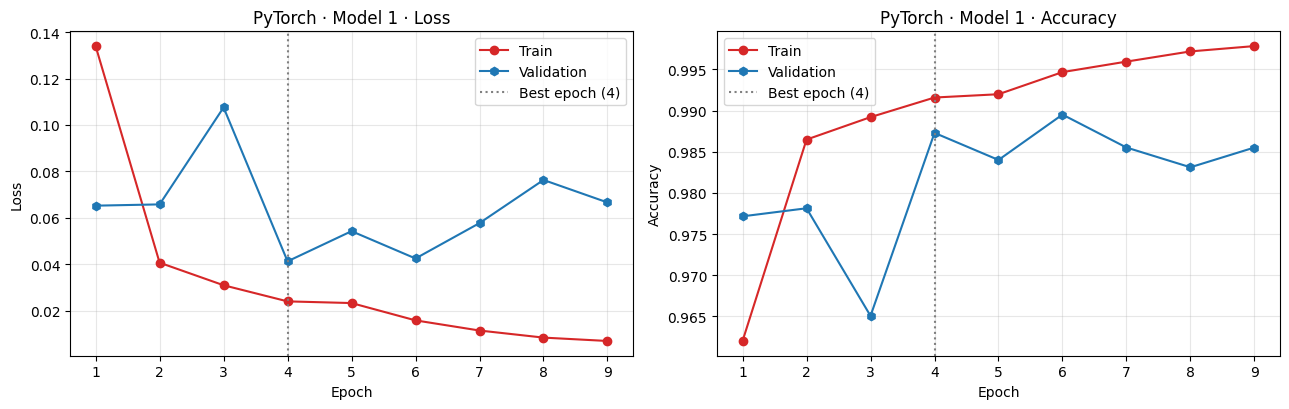

              precision    recall  f1-score   support

     Arborio     0.9932    0.9671    0.9800      2250
     Basmati     0.9872    0.9920    0.9896      2250
      Ipsala     0.9991    0.9982    0.9987      2250
     Jasmine     0.9880    0.9840    0.9860      2250
   Karacadag     0.9714    0.9969    0.9840      2250

    accuracy                         0.9876     11250
   macro avg     0.9878    0.9876    0.9876     11250
weighted avg     0.9878    0.9876    0.9876     11250



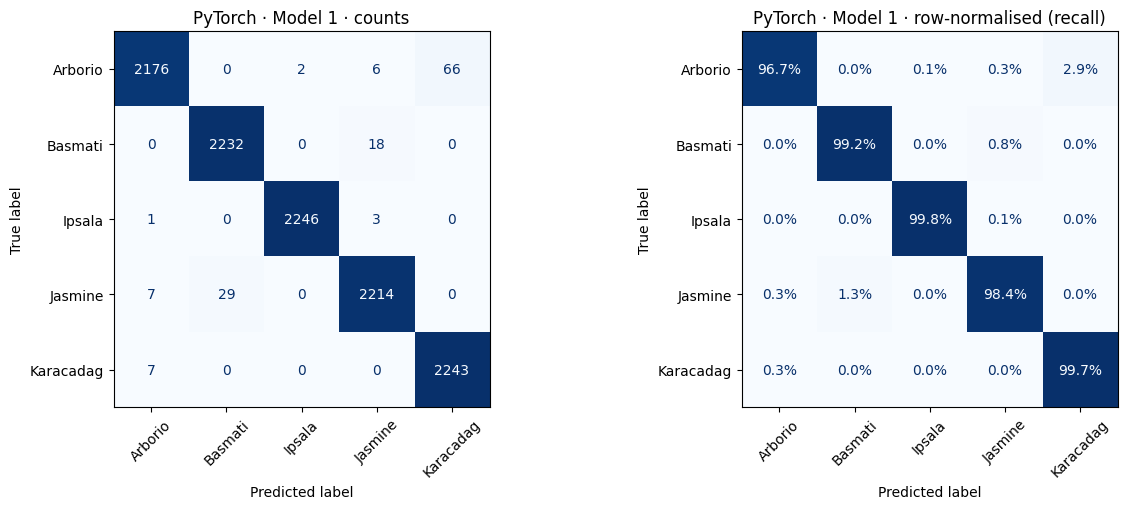

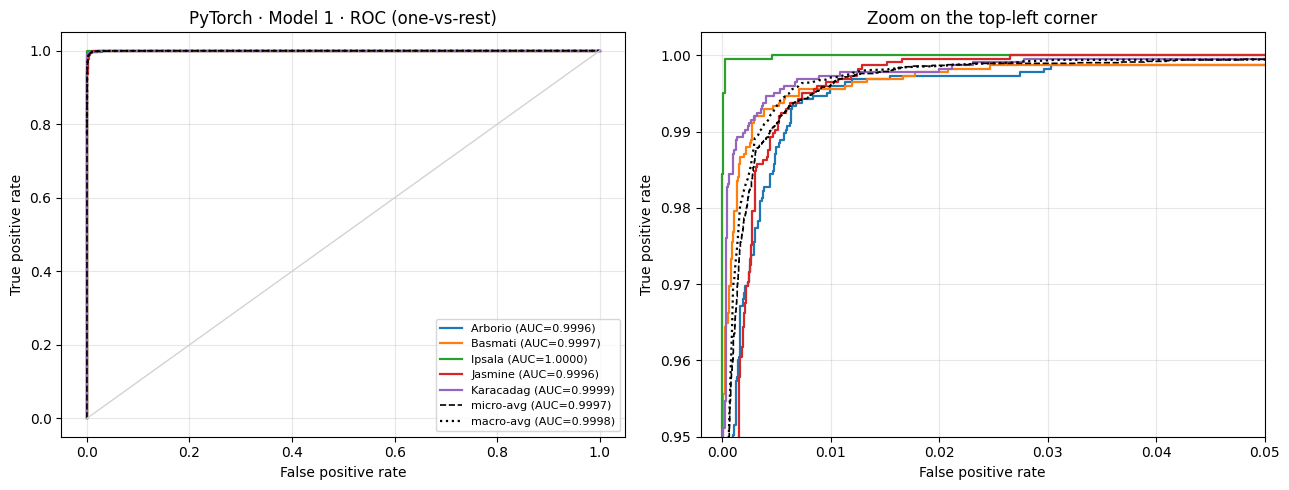

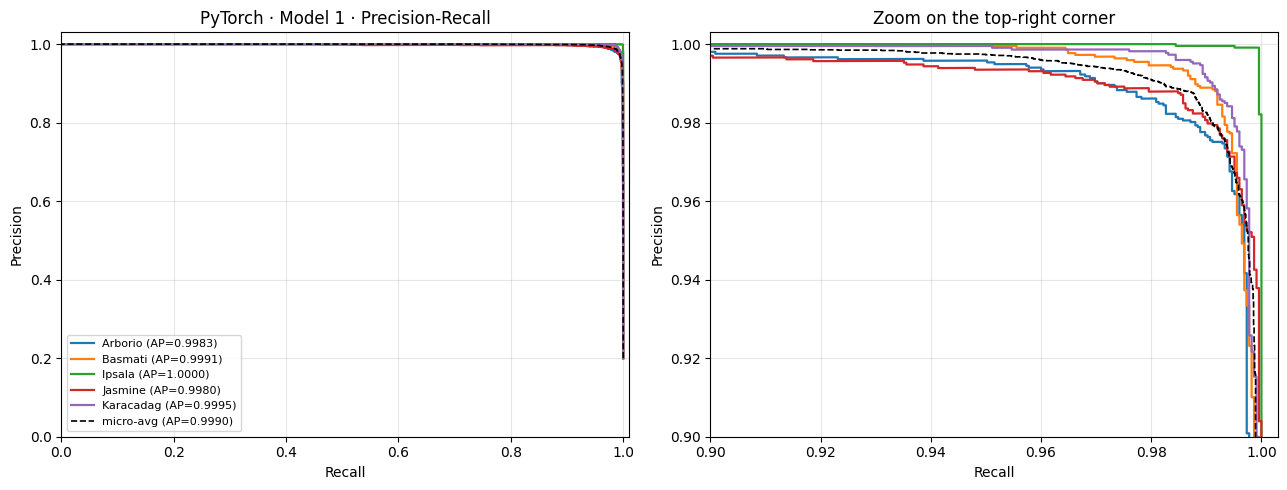

In [19]:
report(res_pt1)

### 2.3 Model 2: regularised

Same architecture as Model 1, plus **L2 penalty** on the conv and hidden linear weights (added explicitly to the loss, exactly like Keras' `l2`), an **extra Linear(100)** layer and **Dropout(0.5)**.

In [20]:
set_seed_torch()
pt_model_2 = RiceCNN(regularized=True)
print(pt_model_2)
print(f"\nTrainable parameters: {sum(p.numel() for p in pt_model_2.parameters() if p.requires_grad):,}")

RiceCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=175232, out_features=300, bias=True)
    (1): ReLU()
    (2): Linear(in_features=300, out_features=100, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=100, out_features=5, bias=True)
  )
)

Trainable parameters: 52,601,401


In [21]:
res_pt2 = train_torch(pt_model_2, "Model 2")
PT_MODELS[res_pt2["key"]] = pt_model_2

Epoch 1/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  1/20 - loss: 0.3861 - acc: 0.9433 - val_loss: 0.2031 - val_acc: 0.9731


Epoch 2/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  2/20 - loss: 0.1967 - acc: 0.9706 - val_loss: 0.1618 - val_acc: 0.9744


Epoch 3/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch  3/20 - loss: 0.1452 - acc: 0.9779 - val_loss: 0.1147 - val_acc: 0.9844


... (30 outputs left out)

Epoch 19/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch 19/20 - loss: 0.0735 - acc: 0.9902 - val_loss: 0.0641 - val_acc: 0.9909


Epoch 20/20:   0%|          | 0/1641 [00:00<?, ?it/s]

Epoch 20/20 - loss: 0.0765 - acc: 0.9890 - val_loss: 0.0738 - val_acc: 0.9902


PyTorch · Model 2   |   params: 52,601,401   epochs run: 20 (best: 18)   train time: 1615s
TEST  accuracy: 0.9924   cross-entropy: 0.0240   macro ROC-AUC: 0.9999   macro avg-precision: 0.9994



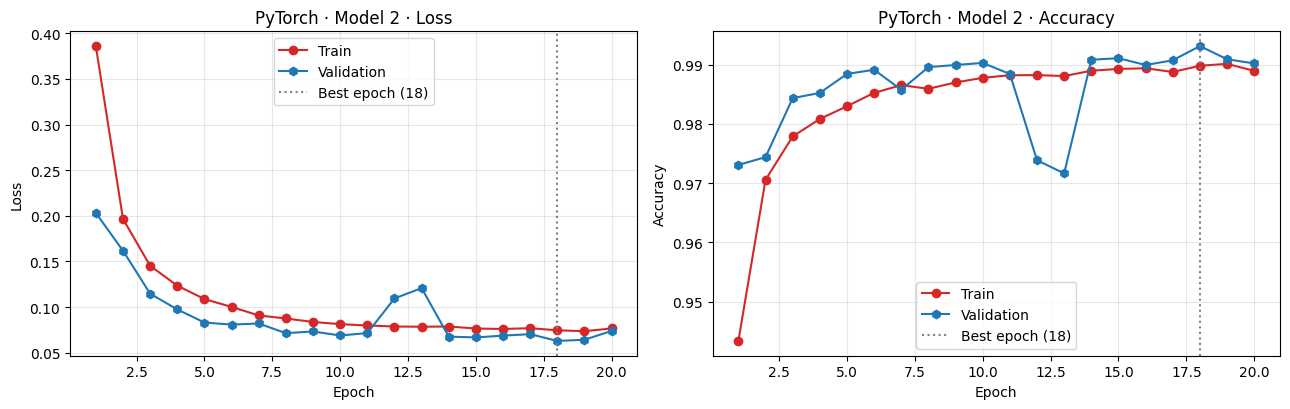

              precision    recall  f1-score   support

     Arborio     0.9807    0.9938    0.9872      2250
     Basmati     0.9929    0.9951    0.9940      2250
      Ipsala     0.9991    1.0000    0.9996      2250
     Jasmine     0.9915    0.9876    0.9895      2250
   Karacadag     0.9982    0.9858    0.9919      2250

    accuracy                         0.9924     11250
   macro avg     0.9925    0.9924    0.9924     11250
weighted avg     0.9925    0.9924    0.9924     11250



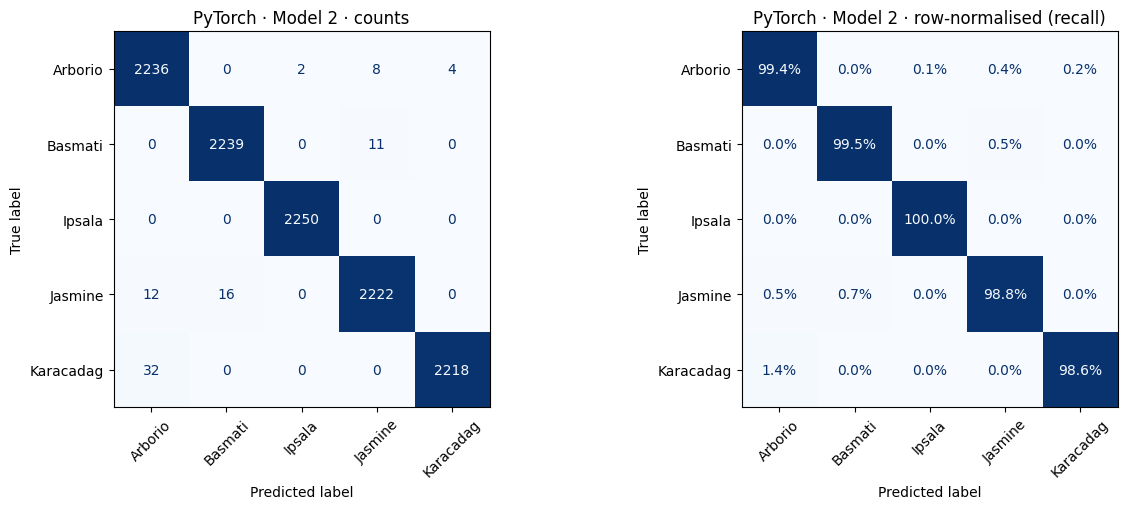

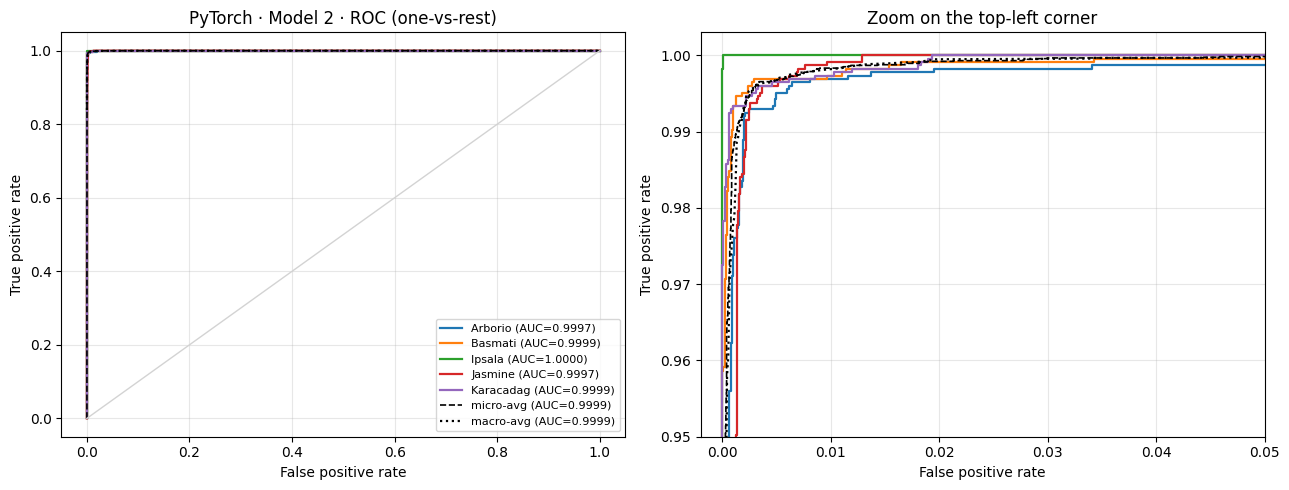

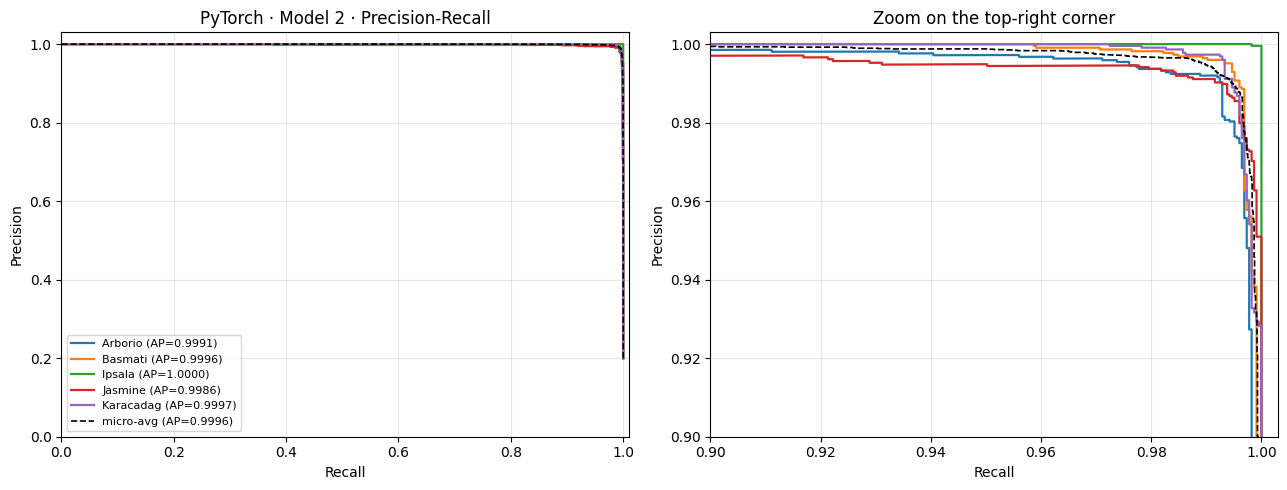

In [22]:
report(res_pt2)

### 2.4 Final PyTorch model

Chosen on the **validation cross-entropy**, same rule as in the TensorFlow section.

Selected: PyTorch · Model 2   (lowest validation cross-entropy: 0.0232)


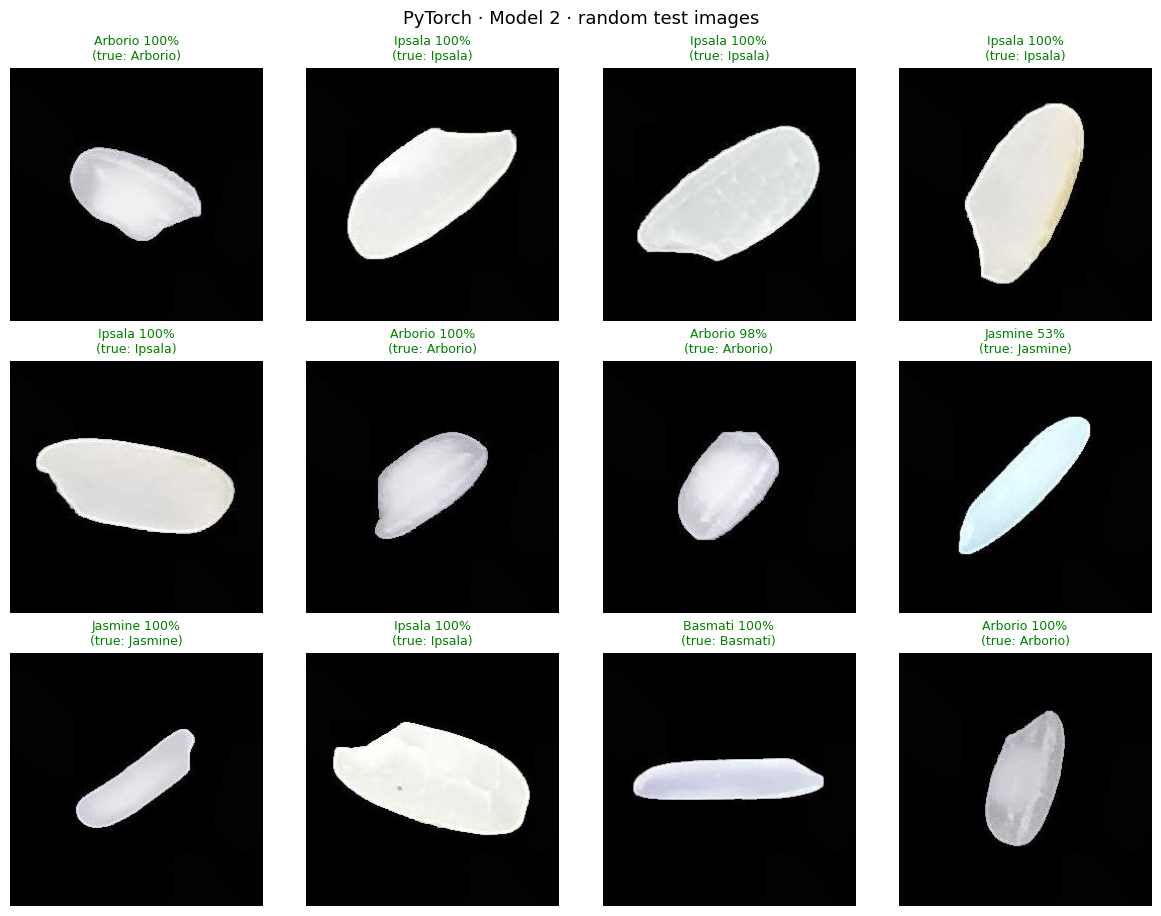

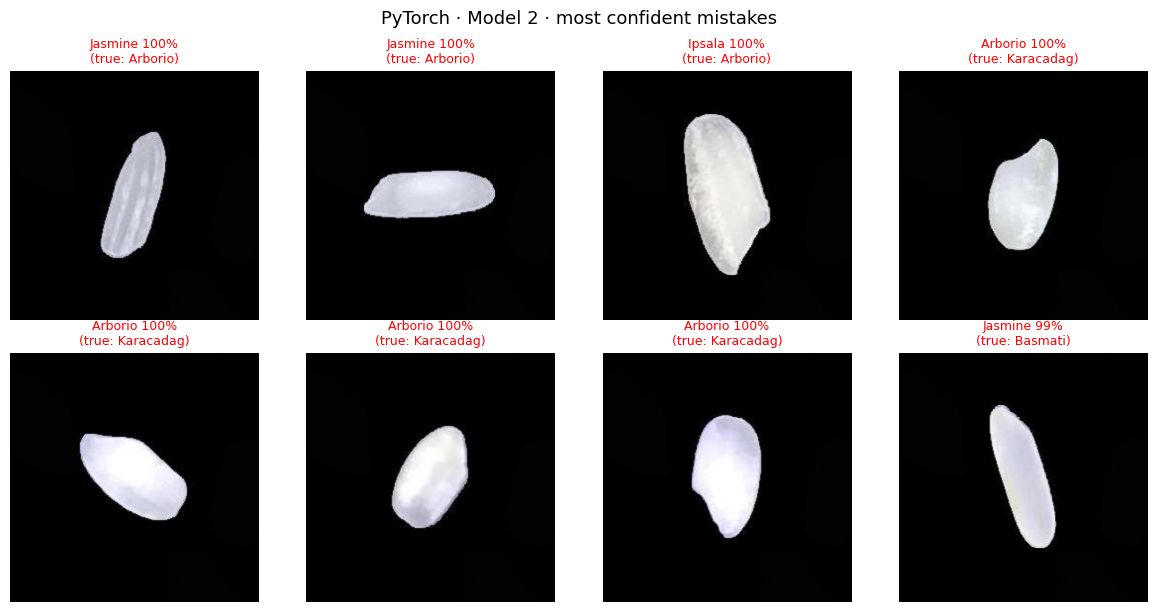

In [23]:
pt_candidates = {k: v for k, v in RESULTS.items() if v["framework"] == "PyTorch"}
pt_final_key = min(pt_candidates, key=lambda k: val_cross_entropy(pt_candidates[k]))
pt_final = RESULTS[pt_final_key]
print(f"Selected: PyTorch · {pt_final['model']}   (lowest validation cross-entropy: {val_cross_entropy(pt_final):.4f})")

if pt_final_key in PT_MODELS:
    torch.save(PT_MODELS[pt_final_key].state_dict(), OUT_DIR / "pytorch_final_model.pt")

show_predictions(pt_final, n=12)                      # same 12 images as the TensorFlow section
show_predictions(pt_final, n=8, only_errors=True)

<a class="anchor" id="sec3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">3 · Side-by-Side Comparison: Accuracy &amp; Training Behaviour</p>

Everything below is read from the saved results of this run. Both frameworks were evaluated on the **same test images**, with the **same metric code**. Speed, memory and inference are judged in Section 4, because wall-clock training time here mixes GPU compute with data loading.

In [24]:
load_saved_results()
ORDER = ["tensorflow_model1", "pytorch_model1", "tensorflow_model2", "pytorch_model2"]
missing = [k for k in ORDER if k not in RESULTS]
if missing:
    raise RuntimeError(f"Missing results for {missing}. Run Sections 1 and 2 first.")

SHORT = {"tensorflow": "TF", "pytorch": "PT"}
def label(k): return f"{SHORT[RESULTS[k]['framework'].lower()]} · {RESULTS[k]['model']}"
def color(k): return FW_COLORS[RESULTS[k]["framework"]]

# the architectures are meant to be identical, so the parameter counts must match
for m in ("model1", "model2"):
    a, b = RESULTS[f"tensorflow_{m}"]["n_params"], RESULTS[f"pytorch_{m}"]["n_params"]
    print(f"{m}: TF {a:,} vs PT {b:,} parameters ->", "match" if a == b else "MISMATCH, check the architectures")

model1: TF 52,572,301 vs PT 52,572,301 parameters -> match
model2: TF 52,601,401 vs PT 52,601,401 parameters -> match


### 3.1 Summary table (test set)

In [25]:
summary = pd.DataFrame({label(k): summarize(RESULTS[k]) for k in ORDER}).T.astype(float)
summary.to_csv(OUT_DIR / "comparison_summary.csv")

higher = ["Train acc", "Val acc", "Test acc", "Precision (macro)", "Recall (macro)", "F1 (macro)",
          "ROC-AUC (macro)", "ROC-AUC (micro)", "Avg precision (macro)", "Avg precision (micro)"]
lower  = ["Val CE", "Test CE", "Train time (s)", "Sec/epoch"]
try:
    styled = (summary.style
              .format({**{c: "{:.4f}" for c in higher + ["Val CE", "Test CE"]},
                       "Params": "{:,.0f}", "Epochs run": "{:.0f}", "Best epoch": "{:.0f}",
                       "Train time (s)": "{:.0f}", "Sec/epoch": "{:.1f}"})
              .highlight_max(subset=higher, color="#c6efce")
              .highlight_min(subset=lower, color="#c6efce"))
    display(styled)
except Exception:
    display(summary)
print("Green = best value in the column. 'Val CE' and 'Test CE' are plain cross-entropy computed from the softmax "
      "probabilities (identical formula for both frameworks, no L2 term). 'Train acc' / 'Val acc' are the "
      "per-epoch values from the training log. Training time here includes data loading, so it is NOT a clean "
      "framework speed comparison: see Section 4 for that.")

,Params,Epochs run,Best epoch,Train time (s),Sec/epoch,Train acc,Val acc,Val CE,Test acc,Test CE,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (macro),ROC-AUC (micro),Avg precision (macro),Avg precision (micro)
TF · Model 1,"52,572,301",8,3,451,56.4,0.9912,0.9912,0.0269,0.9926,0.0246,0.9926,0.9926,0.9926,0.9998,0.9998,0.9989,0.9993
PT · Model 1,"52,572,301",9,4,690,76.6,0.9916,0.9873,0.0413,0.9876,0.0398,0.9878,0.9876,0.9876,0.9998,0.9997,0.9990,0.9990
TF · Model 2,"52,601,401",17,12,895,52.6,0.9841,0.9880,0.0339,0.9882,0.0354,0.9883,0.9882,0.9882,0.9997,0.9998,0.9986,0.9991
PT · Model 2,"52,601,401",20,18,1615,80.7,0.9898,0.9932,0.0232,0.9924,0.0240,0.9925,0.9924,0.9924,0.9999,0.9999,0.9994,0.9996


Green = best value in the column. 'Val CE' and 'Test CE' are plain cross-entropy computed from the softmax probabilities (identical formula for both frameworks, no L2 term). 'Train acc' / 'Val acc' are the per-epoch values from the training log. Training time here includes data loading, so it is NOT a clean framework speed comparison: see Section 4 for that.


### 3.2 Training curves: TensorFlow vs PyTorch

Solid = training, dashed = validation. Each row is one model; the curves of the two frameworks should look alike if the setups really match.

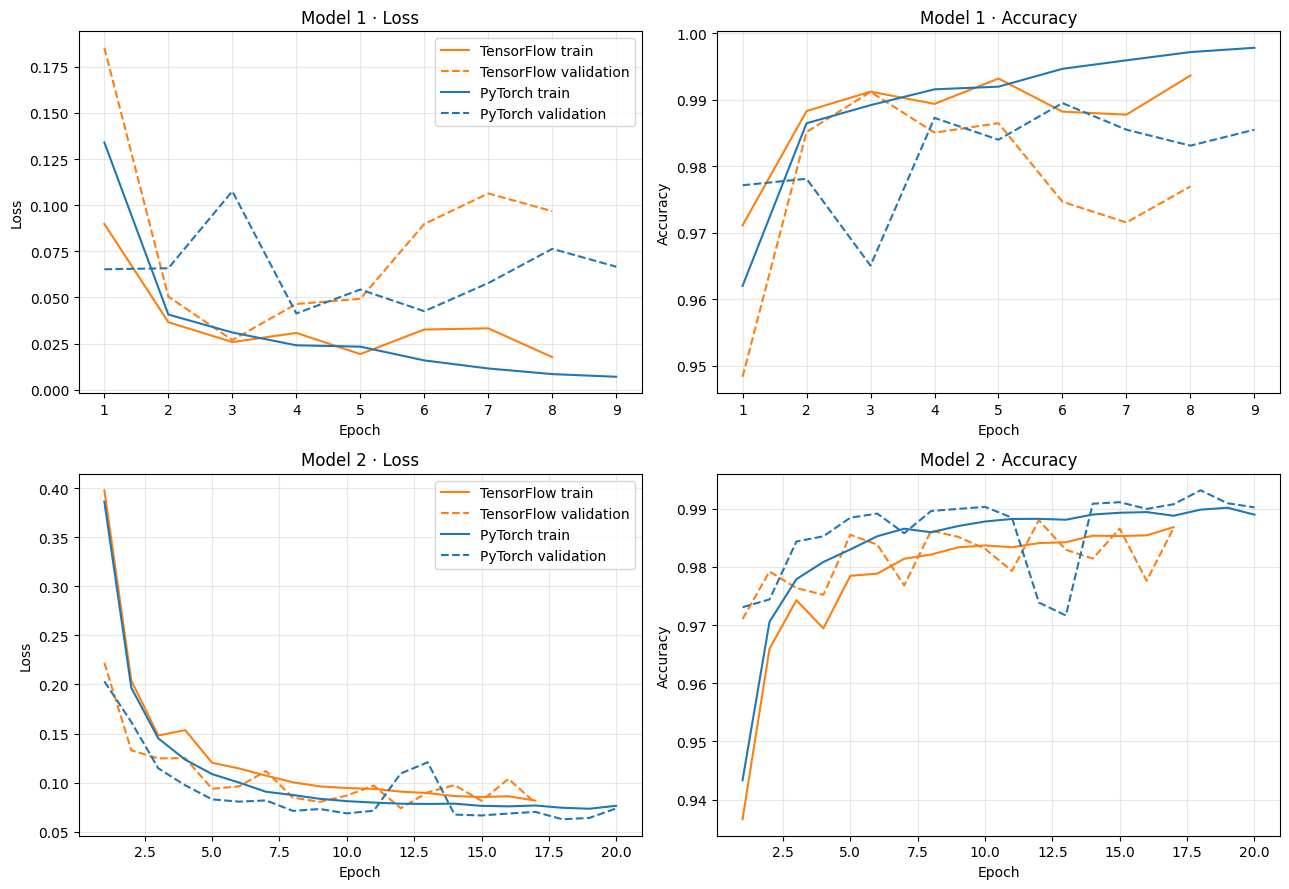

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, m in enumerate(("model1", "model2")):
    for k in (f"tensorflow_{m}", f"pytorch_{m}"):
        h, c = RESULTS[k]["history"], color(k)
        ep = np.arange(1, len(h["loss"]) + 1)
        for col, (tr, va, name) in enumerate([("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy")]):
            axes[row, col].plot(ep, h[tr], "-", color=c, label=f"{RESULTS[k]['framework']} train")
            axes[row, col].plot(ep, h[va], "--", color=c, label=f"{RESULTS[k]['framework']} validation")
            axes[row, col].set_title(f"{RESULTS[k]['model']} · {name}")
            axes[row, col].set_xlabel("Epoch"); axes[row, col].grid(alpha=.3)
    axes[row, 0].legend(); axes[row, 0].set_ylabel("Loss"); axes[row, 1].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

### 3.3 Confusion matrices (row-normalised, test set)

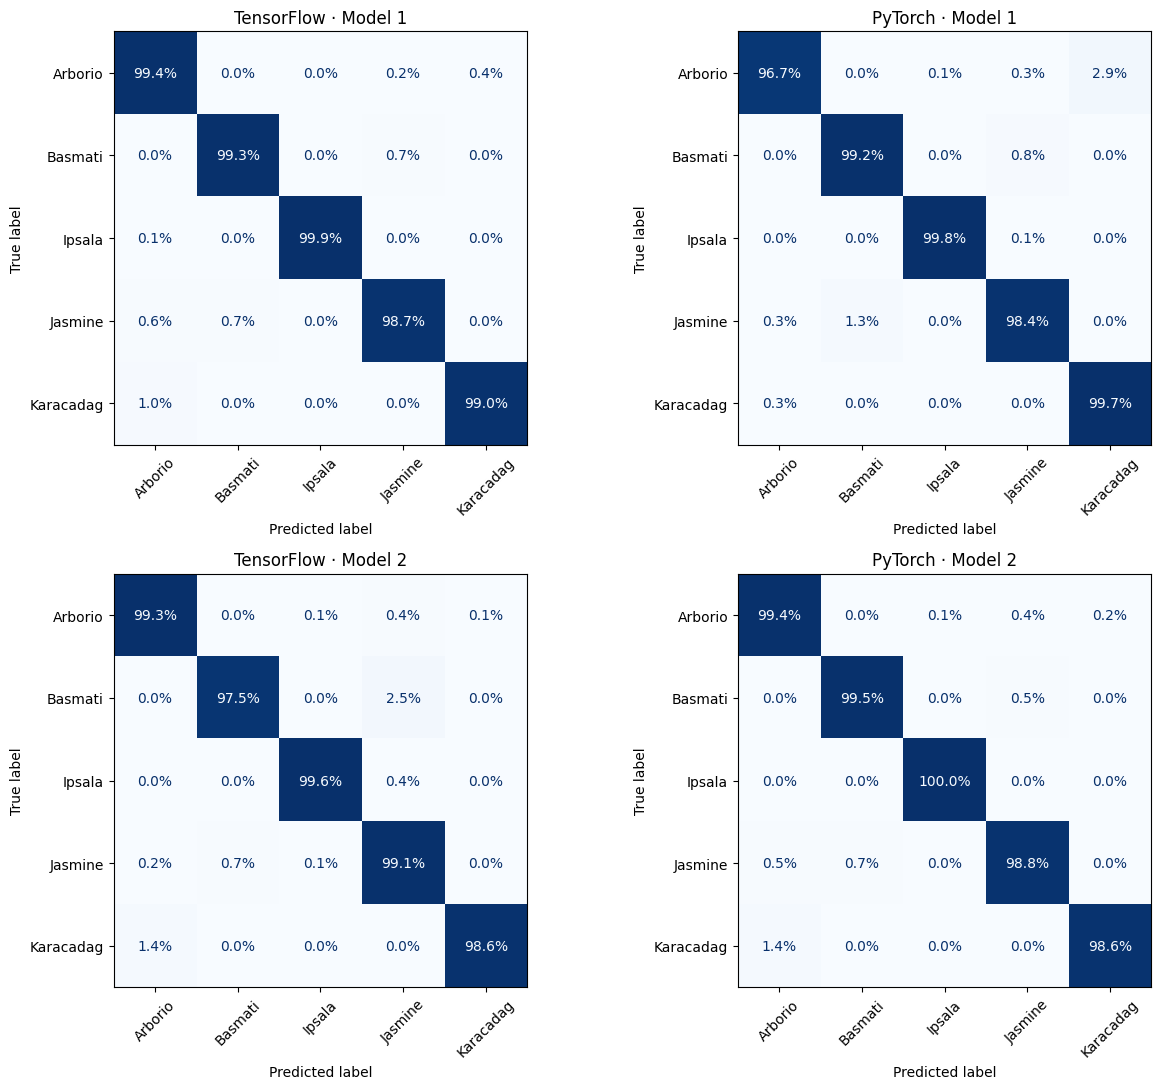

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for r, m in enumerate(("model1", "model2")):
    for c, fw in enumerate(("tensorflow", "pytorch")):
        res = RESULTS[f"{fw}_{m}"]
        ConfusionMatrixDisplay.from_predictions(res["y_true"], res["y_prob"].argmax(1), display_labels=CLASS_NAMES,
                                                ax=axes[r, c], cmap="Blues", colorbar=False, xticks_rotation=45,
                                                normalize="true", values_format=".1%")
        axes[r, c].set_title(f"{res['framework']} · {res['model']}"); axes[r, c].grid(False)
plt.tight_layout(); plt.show()

### 3.4 ROC and precision-recall curves for all four models

Colour = framework, solid = Model 1, dashed = Model 2. The right-hand plots zoom into the corner where the curves of near-perfect classifiers live.

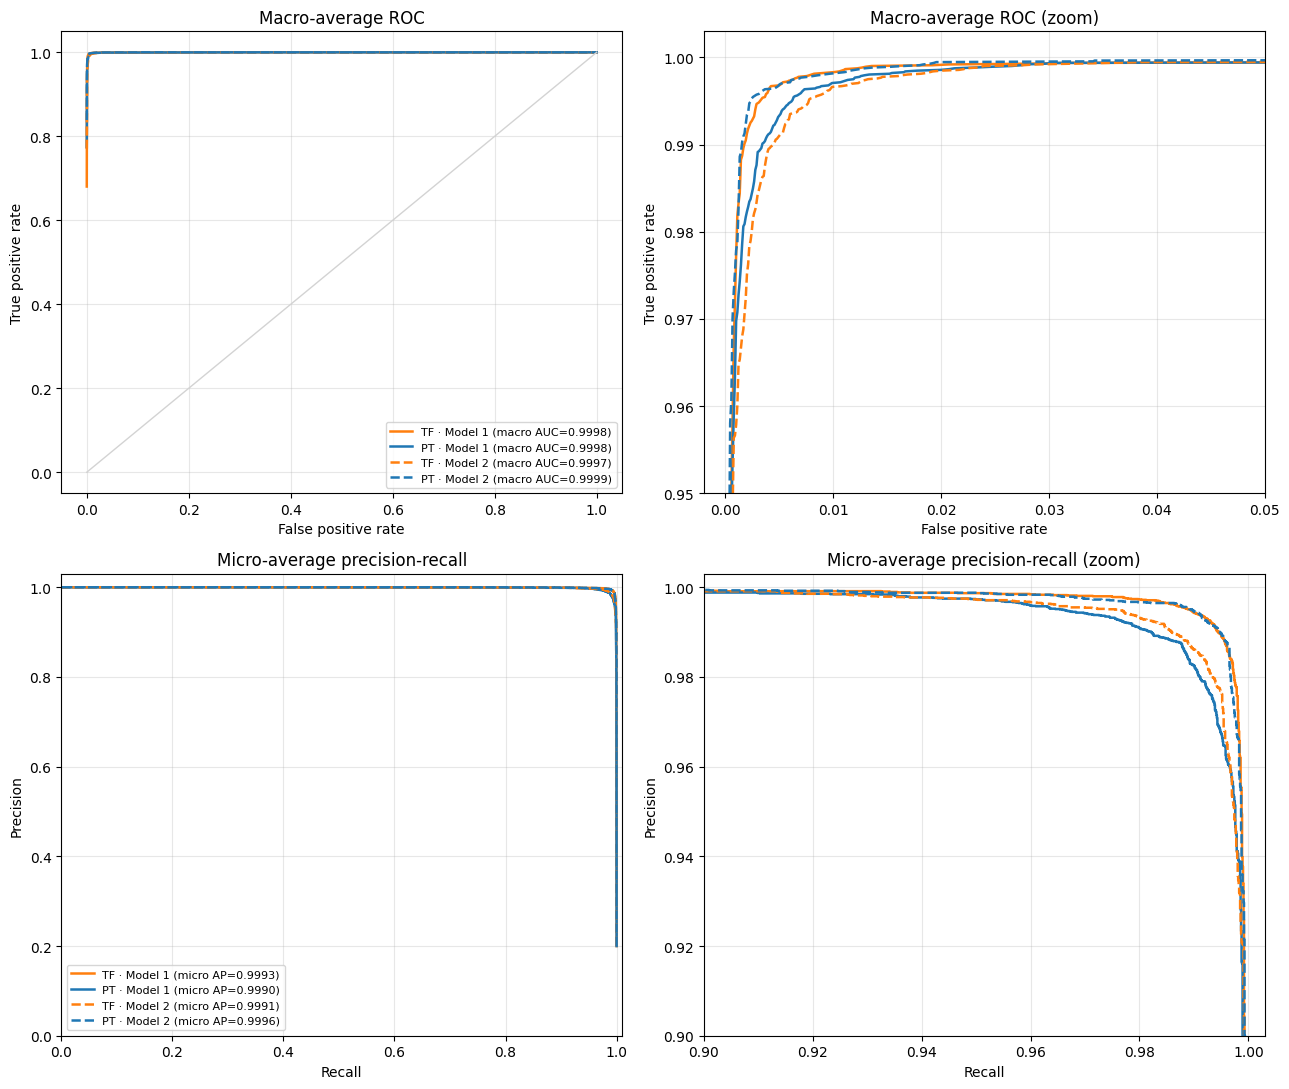

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for k in ORDER:
    ls = "-" if k.endswith("model1") else "--"
    roc, pr = roc_data(RESULTS[k]["y_true"], RESULTS[k]["y_prob"]), pr_data(RESULTS[k]["y_true"], RESULTS[k]["y_prob"])
    for ax in axes[0]:
        ax.plot(*roc["macro"][:2], ls, color=color(k), lw=1.8, label=f"{label(k)} (macro AUC={roc['macro'][2]:.4f})")
    for ax in axes[1]:
        ax.plot(*pr["micro"][:2], ls, color=color(k), lw=1.8, label=f"{label(k)} (micro AP={pr['micro'][2]:.4f})")
axes[0, 0].plot([0, 1], [0, 1], color="lightgray", lw=1)
axes[0, 1].set_xlim(-0.002, 0.05); axes[0, 1].set_ylim(0.95, 1.003)
axes[1, 0].set_xlim(0, 1.01); axes[1, 0].set_ylim(0, 1.03)
axes[1, 1].set_xlim(0.9, 1.003); axes[1, 1].set_ylim(0.9, 1.003)
for ax in axes[0]:
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
for ax in axes[1]:
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
axes[0, 0].set_title("Macro-average ROC"); axes[0, 1].set_title("Macro-average ROC (zoom)")
axes[1, 0].set_title("Micro-average precision-recall"); axes[1, 1].set_title("Micro-average precision-recall (zoom)")
axes[0, 0].legend(loc="lower right", fontsize=8); axes[1, 0].legend(loc="lower left", fontsize=8)
for ax in axes.ravel():
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3.5 Which rice varieties are hardest? (per-class F1)

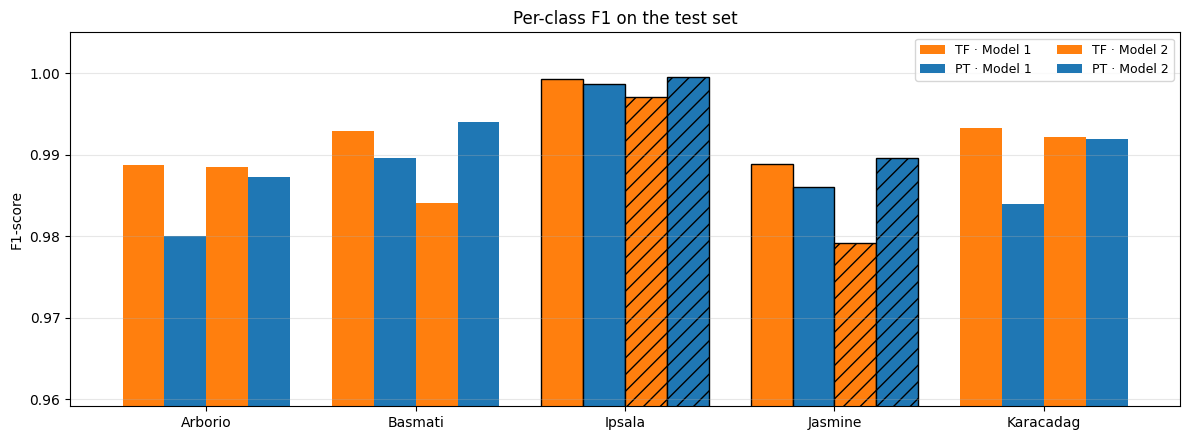

,TF · Model 1,PT · Model 1,TF · Model 2,PT · Model 2
Arborio,0.9887,0.9800,0.9885,0.9872
Basmati,0.9929,0.9896,0.9841,0.9940
Ipsala,0.9993,0.9987,0.9971,0.9996
Jasmine,0.9889,0.9860,0.9791,0.9895
Karacadag,0.9933,0.9840,0.9922,0.9919


In [29]:
f1 = pd.DataFrame({label(k): precision_recall_fscore_support(
        RESULTS[k]["y_true"], RESULTS[k]["y_prob"].argmax(1), labels=list(range(NUM_CLASSES)),
        zero_division=0)[2] for k in ORDER}, index=CLASS_NAMES)

ax = f1.plot.bar(figsize=(12, 4.5), width=0.8, color=[color(k) for k in ORDER],
                 edgecolor=["black" if k.endswith("model2") else "none" for k in ORDER])
for patch, k in zip(ax.containers, ORDER):          # hatch Model 2 bars so the two models are distinguishable
    if k.endswith("model2"):
        for p in patch: p.set_hatch("//")
lo = max(0.0, float(f1.values.min()) - 0.02)
ax.set_ylim(lo, 1.005); ax.set_ylabel("F1-score"); ax.set_title("Per-class F1 on the test set")
ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0); plt.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
display(f1.style.format("{:.4f}").highlight_max(axis=1, color="#c6efce") if hasattr(f1, "style") else f1)

### 3.6 Automatic take-aways

In [30]:
best_acc = summary["Test acc"].astype(float).idxmax()
best_auc = summary["ROC-AUC (macro)"].astype(float).idxmax()
print(f"Highest test accuracy : {best_acc}  ({summary.loc[best_acc, 'Test acc']:.4f})")
print(f"Highest macro ROC-AUC : {best_auc}  ({summary.loc[best_auc, 'ROC-AUC (macro)']:.4f})")
print("Speed, memory and inference are NOT judged here (see Section 4).\n")

for m in ("model1", "model2"):
    tf_r, pt_r = summary.loc[label(f"tensorflow_{m}")], summary.loc[label(f"pytorch_{m}")]
    gap_tf = float(tf_r["Train acc"] - tf_r["Val acc"]); gap_pt = float(pt_r["Train acc"] - pt_r["Val acc"])
    print(f"{RESULTS[f'tensorflow_{m}']['model']}: test-accuracy difference TF - PT = {float(tf_r['Test acc'] - pt_r['Test acc']):+.4f} | "
          f"train-val accuracy gap TF {gap_tf:+.4f}, PT {gap_pt:+.4f}")

print("\nTrain-minus-validation accuracy at the best epoch is the over-fitting gap; compare Model 1 with Model 2 "
      "to see what the L2 + dropout regularisation bought. Differences of a few hundredths of a percent between "
      "frameworks are within run-to-run noise (GPU kernels are not bit-exact), so re-run with other SEED values "
      "before calling a winner.")

Highest test accuracy : TF · Model 1  (0.9926)
Highest macro ROC-AUC : PT · Model 2  (0.9999)
Speed, memory and inference are NOT judged here (see Section 4).

Model 1: test-accuracy difference TF - PT = +0.0050 | train-val accuracy gap TF +0.0000, PT +0.0043
Model 2: test-accuracy difference TF - PT = -0.0043 | train-val accuracy gap TF -0.0039, PT -0.0033

Train-minus-validation accuracy at the best epoch is the over-fitting gap; compare Model 1 with Model 2 to see what the L2 + dropout regularisation bought. Differences of a few hundredths of a percent between frameworks are within run-to-run noise (GPU kernels are not bit-exact), so re-run with other SEED values before calling a winner.


<a class="anchor" id="sec4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">4 · Controlled Benchmarks: Speed, Memory, Input Pipeline, Inference</p>

Sections 1 to 3 answered *which framework gives the better model*. This section answers *which one is cheaper and faster to run*, under controlled conditions:

* compute-only training speed and memory, with identical tensors already on the GPU (4.3)
* input pipelines on their own and end-to-end training (4.4)
* inference latency, throughput, cold start and CPU inference (4.5)

Every GPU timing has warm-up, ends with a hard synchronisation, is repeated, and measures TensorFlow and PyTorch back to back. Differences under 5% are called ties.

### 4.1 Environment and fairness controls

In [31]:
import gc, glob, json, subprocess, itertools, sys
from collections import defaultdict

# free what the training sections still hold (GPU memory, DataLoader worker processes)
for _name in ("tf_model_1", "tf_model_2", "pt_model_1", "pt_model_2", "pt_train", "pt_val", "pt_test"):
    globals().pop(_name, None)
for _d in ("TF_MODELS", "PT_MODELS"):
    globals().get(_d, {}).clear()
gc.collect(); torch.cuda.empty_cache(); keras.backend.clear_session()

# ---------------- benchmark configuration ----------------   # BENCHMARK_CONFIG_CELL
BATCH         = BATCH_SIZE          # same batch size as in training
QUICK         = SMOKE_TEST          # True = fewer repeats/steps
WARMUP_STEPS  = 10 if QUICK else 30
TIMED_STEPS   = 30 if QUICK else 100
REPEATS       = 2 if QUICK else 5
TIE_THRESHOLD = 0.05                # differences below 5 % are reported as a tie
N_CPU         = os.cpu_count() or 1
assert DEVICE.type == "cuda", "The benchmarks need a GPU (select GPU T4 x2 in the notebook settings)."

# ---------------- GPU assignment ----------------
# TensorFlow keeps every bit of GPU memory it has grown into and never gives it back, so two frameworks sharing one GPU
# end up starving each other (PyTorch inference ran out of memory that way). With two identical T4s each gets its own.
if torch.cuda.device_count() >= 2:
    torch.cuda.set_device(1)                       # PyTorch -> GPU 1 ("cuda" now means cuda:1); TensorFlow stays on GPU 0
    _same = torch.cuda.get_device_name(0) == torch.cuda.get_device_name(1)
    print(f"TensorFlow -> GPU 0 ({torch.cuda.get_device_name(0)}) | PyTorch -> GPU 1 ({torch.cuda.get_device_name(1)})"
          + ("" if _same else "   WARNING: the two GPUs differ, compare with care"))
else:
    print("Only one GPU visible: both frameworks share it, so PyTorch GPU benchmarks may run out of memory.")

# ---------------- PyTorch compiler backend ----------------
# torch.compile's default backend (inductor) needs Triton, which some Kaggle images lack. Try to install it when the
# notebook has internet access; otherwise fall back to the Triton-free "cudagraphs" backend (launch-overhead removal only).
def _has_triton():
    try:
        from torch.utils._triton import has_triton
        return bool(has_triton())
    except Exception:
        return False

TRY_INSTALL_TRITON = True
if not _has_triton() and TRY_INSTALL_TRITON:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--retries", "0", "--timeout", "20", "triton==3.1.0"],
                       capture_output=True, timeout=240)
        import importlib; importlib.invalidate_caches()
        from torch.utils._triton import has_triton as _ht
        _ht.cache_clear()
    except Exception:
        pass
PT_COMPILE_BACKEND = "inductor" if _has_triton() else "cudagraphs"
print("torch.compile backend:", PT_COMPILE_BACKEND,
      "" if PT_COMPILE_BACKEND == "inductor" else "(Triton is not available here, so the fused-kernel backend cannot be used)")

TensorFlow -> GPU 0 (Tesla T4) | PyTorch -> GPU 1 (Tesla T4)
torch.compile backend: cudagraphs (Triton is not available here, so the fused-kernel backend cannot be used)


In [32]:
import traceback
try:
    def _cmd(c):
        try:
            return subprocess.check_output(c, shell=True, stderr=subprocess.DEVNULL, text=True).strip()
        except Exception:
            return "n/a"

    tf_build = tf.sysconfig.get_build_info()
    ENV = {
        "GPU for TensorFlow (GPU:0)": torch.cuda.get_device_name(0),
        "GPU for PyTorch": torch.cuda.get_device_name(torch.cuda.current_device()),
        "GPUs visible": f"TF {len(tf.config.list_physical_devices('GPU'))} / PyTorch {torch.cuda.device_count()}",
        "NVIDIA driver": _cmd("nvidia-smi --query-gpu=driver_version --format=csv,noheader | head -1"),
        "CPU cores": N_CPU,
        "TensorFlow / Keras": f"{tf.__version__} / {keras.__version__}",
        "TF built with CUDA / cuDNN": f"{tf_build.get('cuda_version')} / {tf_build.get('cudnn_version')}",
        "PyTorch": torch.__version__,
        "PyTorch built with CUDA / cuDNN": f"{torch.version.cuda} / {torch.backends.cudnn.version()}",
        "Batch size / image size": f"{BATCH} / {IMG_SIZE}x{IMG_SIZE}",
        "Timing protocol": f"{WARMUP_STEPS} warm-up + {TIMED_STEPS} timed steps x {REPEATS} repeats, hard GPU sync",
    }
    display(pd.DataFrame({"value": ENV}))
    json.dump({k: str(v) for k, v in ENV.items()}, open(OUT_DIR / "environment.json", "w"), indent=2)
except Exception as _e:
    print('[Section 4-6 cell 1] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


,value
GPU for TensorFlow (GPU:0),Tesla T4
GPU for PyTorch,Tesla T4
GPUs visible,TF 2 / PyTorch 2
NVIDIA driver,580.178.04
CPU cores,4
TensorFlow / Keras,2.17.1 / 3.5.0
TF built with CUDA / cuDNN,12.3 / 8
PyTorch,2.5.1+cu121
PyTorch built with CUDA / cuDNN,12.1 / 90100
Batch size / image size,32 / 150x150


**Controls applied to every measurement**

| Control | How |
|---|---|
| Same hardware | Two identical T4s in one kernel: TensorFlow on GPU 0, PyTorch on GPU 1. Each framework has its own GPU, so neither memory pool can starve the other (TensorFlow never returns GPU memory it has grown into) |
| Same model, same batch, same data | Identical layers, parameter counts checked; one fixed random batch on the GPU for compute timings |
| No hidden asynchrony | `torch.cuda.synchronize()` for PyTorch; fetching the loss with `.numpy()` for TF, before stopping every timer |
| Warm-up excluded | Compilation, cuDNN autotuning and allocator warm-up happen before timing (the first call is recorded separately as *cold start*) |
| Variance reported | Median and min-max over repeats, not a single run |
| Drift controlled | TF and PyTorch measurements of the same setting run back to back |
| Optimisation level matched | Three tiers per framework: default, compiler (XLA vs `torch.compile`) and fp16 mixed precision |

### 4.2 Equivalent models

Models 1 and 2 are exactly the two CNNs trained above. They are dominated by one huge dense layer (175,232 x 300 weights). Model 3 is added **for the speed and memory benchmarks only** (it is not trained here): a conv-heavy network with four Conv-BatchNorm-ReLU-MaxPool blocks and global average pooling. It tests whether a conclusion drawn on the dense-heavy models also holds for a convolution-dominated workload.

In [33]:
import traceback
try:
    MODELS = ["M1", "M2", "M3"]
    MODEL_DESC = {"M1": "Model 1: baseline (conv + 52M-param dense)",
                  "M2": "Model 2: + L2, extra dense, dropout",
                  "M3": "Model 3: conv-heavy (4 conv blocks, BN, GAP)"}

    # ----------------------------- Keras -----------------------------
    def build_tf(name):
        reg = keras.regularizers.l2(L2_FACTOR) if name == "M2" else None
        L = keras.layers
        if name in ("M1", "M2"):
            layers = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)), L.Rescaling(1.0 / 255),
                      L.Conv2D(32, 3, activation="relu", kernel_regularizer=reg), L.MaxPool2D(2, 2), L.Flatten(),
                      L.Dense(300, activation="relu", kernel_regularizer=reg)]
            if name == "M2":
                layers += [L.Dense(100, activation="relu", kernel_regularizer=reg), L.Dropout(DROPOUT_RATE)]
        else:
            layers = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)), L.Rescaling(1.0 / 255)]
            for c in (32, 64, 128, 256):
                layers += [L.Conv2D(c, 3, padding="same", use_bias=False), L.BatchNormalization(),
                           L.Activation("relu"), L.MaxPool2D(2, 2)]
            layers += [L.GlobalAveragePooling2D()]
        layers.append(L.Dense(NUM_CLASSES, dtype="float32"))     # float32 logits (needed for mixed precision)
        return keras.Sequential(layers, name=f"tf_{name}")

    # ----------------------------- PyTorch -----------------------------
    # Model 1 / Model 2 in PyTorch are the RiceCNN class from Section 2 (identical); only the conv-heavy Model 3 is new.
    class ConvNet(nn.Module):
        def __init__(self):
            super().__init__()
            blocks, c_in = [], 3
            for c in (32, 64, 128, 256):
                blocks += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2, 2)]
                c_in = c
            self.features = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1), nn.Flatten())
            self.classifier = nn.Linear(256, NUM_CLASSES)
            self.apply(keras_style_init)
        def forward(self, x):
            return self.classifier(self.features(x))
        def reg_loss(self):
            return 0.0

    def build_pt(name, device=DEVICE):
        m = RiceCNN(False) if name == "M1" else RiceCNN(True) if name == "M2" else ConvNet()
        return m.to(device)

    # the architectures must match: compare TRAINABLE parameters
    rows = []
    for n in MODELS:
        keras.backend.clear_session()
        a = sum(int(np.prod(w.shape)) for w in build_tf(n).trainable_weights)
        b = sum(p.numel() for p in build_pt(n).parameters() if p.requires_grad)
        rows.append({"model": MODEL_DESC[n], "TF trainable params": a, "PT trainable params": b,
                     "match": "yes" if a == b else "NO, check"})
    display(pd.DataFrame(rows).set_index("model"))

    # what does Keras do by default? (relevant for fairness: XLA changes speed a lot)
    keras.backend.clear_session()
    _m = build_tf("M1")
    _m.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    print("Keras model.compile default -> jit_compile (XLA) resolves to:", getattr(_m, "jit_compile", "n/a"))
    del _m
except Exception as _e:
    print('[Section 4-6 cell 2] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


,TF trainable params,PT trainable params,match
model,,,
Model 1: baseline (conv + 52M-param dense),52572301,52572301,yes
"Model 2: + L2, extra dense, dropout",52601401,52601401,yes
"Model 3: conv-heavy (4 conv blocks, BN, GAP)",390181,390181,yes


Keras model.compile default -> jit_compile (XLA) resolves to: True


### 4.3 Training speed and memory (compute only)

One fixed batch of random pixels sits on the GPU and is fed to a full training step (forward, loss, backward, Adam update) again and again. Nothing else is measured, so any difference here is the framework's own compute path.

Three optimisation tiers per framework, always measured as a TF/PyTorch pair:

| Tier | TensorFlow | PyTorch |
|---|---|---|
| **default** | `tf.function` graph, no XLA | eager |
| **compiler** | `tf.function(jit_compile=True)` (XLA, whole step incl. optimiser) | `torch.compile(model)` (forward + backward; the Adam update stays eager) |
| **fp16** | `mixed_float16` policy + loss scaling | `torch.autocast(fp16)` + `GradScaler` |
| **best effort** | XLA + fp16 together | compile + fp16 together |

The compiler tiers are not perfectly symmetric (XLA also compiles the optimiser, `torch.compile` here does not), which is noted again in the scorecard. If Triton is missing on the machine (as on some Kaggle images) PyTorch's default compiler backend cannot run, and the notebook falls back to the `cudagraphs` backend, which only removes launch overhead and does not fuse kernels; the backend used is printed in the setup cell and noted in the scorecard.

**Important:** `model.compile` / `fit` in Keras 3 turns XLA on by default (see the `jit_compile` line printed above), whereas PyTorch runs eager. So the realistic *out-of-the-box* comparison is TensorFlow's **compiler** tier against PyTorch's **default** tier; the scorecard reports it as its own rows.

In [34]:
import traceback
try:
    def _dynamo_reset():
        from torch import _dynamo            # NOT "import torch._dynamo": inside a function that would shadow the global `torch`
        _dynamo.reset()

    def cleanup():
        """Free memory between benchmark runs. Every step is isolated so that cleanup itself can never stop a run."""
        for fn in (gc.collect, torch.cuda.empty_cache, keras.backend.clear_session, _dynamo_reset):
            try:
                fn()
            except Exception:
                pass

    def ensure_cols(df, cols):
        """Make sure a results table has every column the later cells read, even if all runs of a kind failed."""
        for c in cols:
            if c not in df.columns:
                df[c] = np.nan
        return df

    def stats(ms):
        ms = np.asarray(ms, dtype=float)
        return {"median": float(np.median(ms)), "min": float(ms.min()), "max": float(ms.max())}

    def time_steps(call, sync, warmup=WARMUP_STEPS, steps=TIMED_STEPS, repeats=REPEATS):
        """Returns (first_call_seconds, [ms per step for each repeat]). `call()` runs one step and returns an output."""
        t0 = time.perf_counter()
        out = call(); sync(out)
        first = time.perf_counter() - t0
        for _ in range(max(0, warmup - 1)):
            out = call()
        sync(out)
        per_repeat = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            for _ in range(steps):
                out = call()
            sync(out)
            per_repeat.append((time.perf_counter() - t0) / steps * 1000)
        return first, per_repeat

    tf_sync = lambda out: out.numpy()                      # fetching a value waits for the GPU
    pt_sync = lambda out: torch.cuda.synchronize()

    # ------------------------------------------------------------ TensorFlow training step
    def make_tf_train(name, mode):
        """mode: 'default' | 'compiler' | 'fp16' | 'best' (compiler + fp16).  Returns (step(x, y) -> loss, keep-alive objects)."""
        amp, jit = mode in ("fp16", "best"), mode in ("compiler", "best")
        keras.backend.clear_session()
        keras.mixed_precision.set_global_policy("mixed_float16" if amp else "float32")
        model = build_tf(name)
        opt = keras.optimizers.Adam(LEARNING_RATE)
        if amp:
            opt = keras.mixed_precision.LossScaleOptimizer(opt)
        loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        variables = model.trainable_variables
        opt.build(variables)                                # create Adam slots outside the traced function

        def step_impl(x, y):
            with tf.GradientTape() as tape:
                logits = model(x, training=True)
                loss = loss_fn(y, tf.cast(logits, tf.float32))
                if model.losses:
                    loss += tf.add_n([tf.cast(l, tf.float32) for l in model.losses])
                scaled = opt.scale_loss(loss) if amp else loss
            grads = tape.gradient(scaled, variables)
            opt.apply_gradients(zip(grads, variables))
            return loss

        step = tf.function(step_impl, jit_compile=jit)
        return step, (model, opt)

    # ------------------------------------------------------------ PyTorch training step
    def make_pt_train(name, mode):
        """mode: 'default' (eager) | 'compiler' (torch.compile) | 'fp16' (autocast). Returns (step(x, y) -> loss, objects)."""
        model = build_pt(name).train()
        opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=1e-7)
        ce = nn.CrossEntropyLoss()
        fwd = torch.compile(model, backend=PT_COMPILE_BACKEND) if mode in ("compiler", "best") else model
        use_amp = mode in ("fp16", "best")
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        except Exception:
            scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

        def step(x, y):
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                out = fwd(x)
            loss = ce(out.float(), y) + model.reg_loss()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            return loss
        return step, (model, opt)

    def tf_peak_mb():
        try:
            return tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
        except Exception:
            return float("nan")

    def tf_reset_peak():
        try:
            tf.config.experimental.reset_memory_stats("GPU:0")
        except Exception:
            pass

    def bench_train(framework, name, mode):
        """Compute-only training benchmark for one (framework, model, tier). Returns a result dict."""
        if framework == "TensorFlow":
            with tf.device("/GPU:0"):
                x = tf.random.uniform((BATCH, IMG_SIZE, IMG_SIZE, 3), 0, 255)
                y = tf.random.uniform((BATCH,), 0, NUM_CLASSES, dtype=tf.int32)
                step, keep = make_tf_train(name, mode)
                first, ms = time_steps(lambda: step(x, y), tf_sync)
                tf_reset_peak()                       # steady-state peak: measured after warm-up, so one-off cuDNN autotuning scratch is excluded
                for _ in range(10):
                    out = step(x, y)
                tf_sync(out)
                peak = tf_peak_mb()
        else:
            x = torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
            y = torch.randint(0, NUM_CLASSES, (BATCH,), device=DEVICE)
            step, keep = make_pt_train(name, mode)
            first, ms = time_steps(lambda: step(x, y), pt_sync)
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()   # steady-state peak, measured after warm-up
            for _ in range(10):
                step(x, y)
            torch.cuda.synchronize()
            peak = torch.cuda.max_memory_allocated() / 2**20
        s = stats(ms)
        return {"ms_per_step": s["median"], "ms_min": s["min"], "ms_max": s["max"],
                "img_per_s": BATCH / s["median"] * 1000, "first_call_s": first, "peak_mem_MB": peak}

    TIERS = [("default", "default (TF graph / PT eager)"),
             ("compiler", "compiler (XLA / torch.compile)"),
             ("fp16", "fp16 mixed precision"),
             ("best", "compiler + fp16 (best effort)")]
except Exception as _e:
    print('[Section 4-6 cell 3] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


In [35]:
import traceback
try:
    TRAIN_ROWS = []
    for name in MODELS:
        for mode, tier_label in TIERS:
            for fw in ("TensorFlow", "PyTorch"):                 # adjacent in time -> same GPU conditions
                row = {"model": name, "tier": tier_label, "framework": fw}
                try:
                    row.update(bench_train(fw, name, mode))
                    print(f"{name} | {tier_label:<32} | {fw:<10} | {row['ms_per_step']:7.2f} ms/step | "
                          f"{row['img_per_s']:8.0f} img/s | peak {row['peak_mem_MB']:7.0f} MB | first call {row['first_call_s']:5.1f}s")
                except Exception as e:
                    row["error"] = f"{type(e).__name__}: {str(e)[:160]}"
                    print(f"{name} | {tier_label:<32} | {fw:<10} | FAILED: {row['error']}")
                TRAIN_ROWS.append(row)
                cleanup()
    keras.mixed_precision.set_global_policy("float32")
    train_df = ensure_cols(pd.DataFrame(TRAIN_ROWS), ["model", "tier", "framework", "ms_per_step", "ms_min", "ms_max",
                                                      "img_per_s", "first_call_s", "peak_mem_MB", "error"])
    train_df.to_csv(OUT_DIR / "bench_training_compute.csv", index=False)
except Exception as _e:
    print('[Section 4-6 cell 4] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


M1 | default (TF graph / PT eager)    | TensorFlow |   38.36 ms/step |      834 img/s | peak    2608 MB | first call   1.6s
M1 | default (TF graph / PT eager)    | PyTorch    |   27.44 ms/step |     1166 img/s | peak    1085 MB | first call   0.0s
M1 | compiler (XLA / torch.compile)   | TensorFlow |   18.69 ms/step |     1712 img/s | peak    2958 MB | first call   0.9s
M1 | compiler (XLA / torch.compile)   | PyTorch    |   28.97 ms/step |     1105 img/s | peak     810 MB | first call   2.3s
M1 | fp16 mixed precision             | TensorFlow |   40.56 ms/step |      789 img/s | peak    3713 MB | first call   1.2s
M1 | fp16 mixed precision             | PyTorch    |   28.64 ms/step |     1117 img/s | peak    1027 MB | first call   0.2s
M1 | compiler + fp16 (best effort)    | TensorFlow |   12.94 ms/step |     2474 img/s | peak    4114 MB | first call   2.8s
M1 | compiler + fp16 (best effort)    | PyTorch    |   30.40 ms/step |     1053 img/s | peak     810 MB | first call   0.6s
M2 | def

In [36]:
import traceback
try:
    def pair_table(df, value, lower_is_better=True, fmt="{:.2f}"):
        """TF vs PT side by side, with the ratio and a verdict (ties under TIE_THRESHOLD)."""
        ok = df[df["error"].isna()] if "error" in df.columns else df
        p = ok.pivot_table(index=["model", "tier"], columns="framework", values=value)
        if not {"TensorFlow", "PyTorch"} <= set(p.columns):
            return p
        p["TF / PT"] = p["TensorFlow"] / p["PyTorch"]
        def verdict(r):
            if not np.isfinite(r["TF / PT"]):
                return "n/a (one side missing)"
            if abs(r["TF / PT"] - 1) < TIE_THRESHOLD:
                return "tie"
            tf_better = (r["TF / PT"] < 1) if lower_is_better else (r["TF / PT"] > 1)
            return "TensorFlow" if tf_better else "PyTorch"
        p["better"] = p.apply(verdict, axis=1)
        return p

    print("Training step time, ms (lower is better). TF / PT < 1 means TensorFlow is faster.")
    display(pair_table(train_df, "ms_per_step").style.format({"TensorFlow": "{:.2f}", "PyTorch": "{:.2f}", "TF / PT": "{:.2f}"}))
    print("Peak GPU memory during training steps, MB (lower is better). Allocator accounting differs slightly between frameworks.")
    display(pair_table(train_df, "peak_mem_MB").style.format({"TensorFlow": "{:.0f}", "PyTorch": "{:.0f}", "TF / PT": "{:.2f}"}))
    print("First call (tracing / compilation / autotuning), seconds. This is a one-off cost, excluded from the step times above.")
    display(pair_table(train_df, "first_call_s").style.format({"TensorFlow": "{:.1f}", "PyTorch": "{:.1f}", "TF / PT": "{:.2f}"}))
except Exception as _e:
    print('[Section 4-6 cell 5] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


Training step time, ms (lower is better). TF / PT < 1 means TensorFlow is faster.


Peak GPU memory during training steps, MB (lower is better). Allocator accounting differs slightly between frameworks.


First call (tracing / compilation / autotuning), seconds. This is a one-off cost, excluded from the step times above.


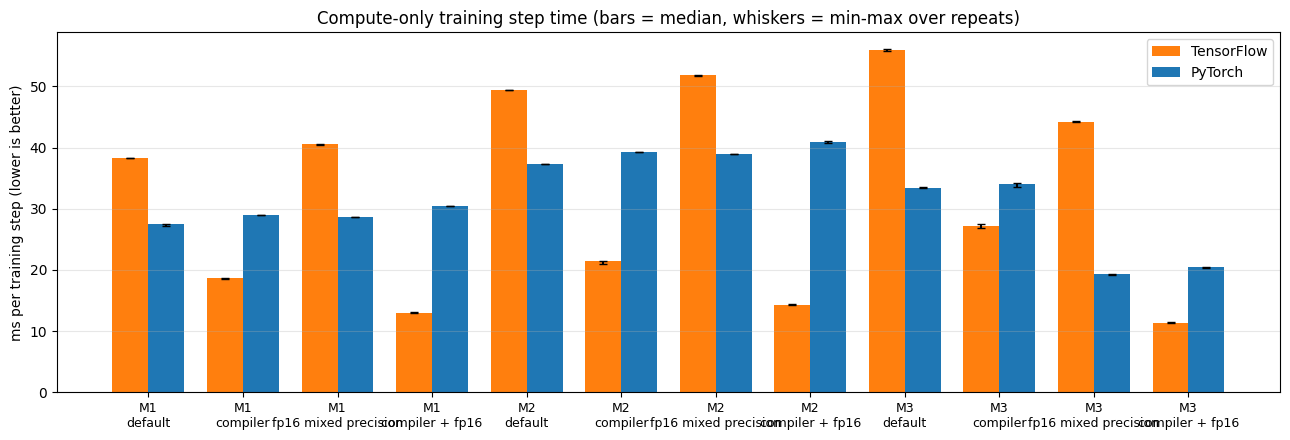

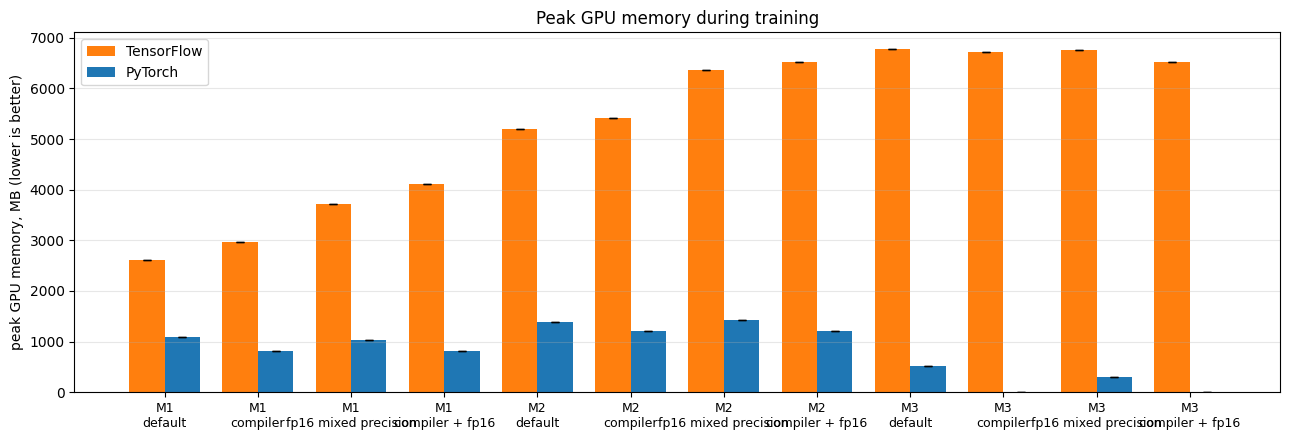

In [37]:
import traceback
try:
    def grouped_bars(df, value, ylabel, title, log=False):
        ok = df[df["error"].isna()] if "error" in df.columns else df
        keys = [(m, t) for m in MODELS for _, t in TIERS if ((ok.model == m) & (ok.tier == t)).any()]
        fig, ax = plt.subplots(figsize=(13, 4.5))
        w = 0.38
        for j, fw in enumerate(("TensorFlow", "PyTorch")):
            vals, lo, hi = [], [], []
            for m, t in keys:
                r = ok[(ok.model == m) & (ok.tier == t) & (ok.framework == fw)]
                if len(r):
                    v = float(r[value].iloc[0]); vals.append(v)
                    lo.append(v - float(r["ms_min"].iloc[0]) if value == "ms_per_step" else 0)
                    hi.append(float(r["ms_max"].iloc[0]) - v if value == "ms_per_step" else 0)
                else:
                    vals.append(np.nan); lo.append(0); hi.append(0)
            ax.bar(np.arange(len(keys)) + (j - 0.5) * w, vals, w, yerr=[lo, hi], capsize=3,
                   color={"TensorFlow": "tab:orange", "PyTorch": "tab:blue"}[fw], label=fw)
        ax.set_xticks(np.arange(len(keys)))
        ax.set_xticklabels([f"{m}\n{t.split(' (')[0]}" for m, t in keys], fontsize=9)
        ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(axis="y", alpha=.3); ax.legend()
        if log: ax.set_yscale("log")
        plt.tight_layout(); plt.show()

    grouped_bars(train_df, "ms_per_step", "ms per training step (lower is better)",
                 "Compute-only training step time (bars = median, whiskers = min-max over repeats)")
    grouped_bars(train_df, "peak_mem_MB", "peak GPU memory, MB (lower is better)", "Peak GPU memory during training")
except Exception as _e:
    print('[Section 4-6 cell 6] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


### 4.4 Input-pipeline throughput and end-to-end training

In Sections 1 and 2 the TensorFlow and PyTorch runs used **different input pipelines** (`tf.data` with native parallel decoding vs a PyTorch `DataLoader` with PIL workers). Training time there therefore mixes two things: how fast the framework computes and how fast its loader feeds the GPU. Here they are separated:

1. **Storage**: first (cold) read of the files vs a repeat (warm) read.
2. **Pipelines alone**: images per second each loader delivers, no model involved.
3. **End-to-end**: a real training step fed by the real pipeline. The slower of (pipeline, compute-only) should be the bottleneck.

In [38]:
import traceback
try:
    # a sample of images for the pipeline benchmarks (same split of the dataset as above)
    N_PER_CLASS = 200 if QUICK else 640                       # 3,200 images in the full run
    _rng = np.random.default_rng(SEED)
    _idx = np.concatenate([_rng.choice(np.where(all_labels == c)[0], size=min(N_PER_CLASS, int((all_labels == c).sum())), replace=False)
                           for c in range(NUM_CLASSES)])
    bench_paths  = [str(all_paths[i]) for i in _idx]
    bench_labels = np.asarray(all_labels)[_idx]
    print(f"{len(bench_paths):,} images sampled for the pipeline benchmarks")

    # ---- 1. storage: the cold read measured in Section 0.2b vs the same files read again now (cached)
    t0 = time.perf_counter()
    for p in COLD_PATHS:
        _read_file(p)
    warm_s = time.perf_counter() - t0
    storage = pd.DataFrame({"pass": ["1st read (cold, Section 0.2b)", "re-read (cached, now)"],
                            "seconds": [COLD_SECONDS, warm_s],
                            "files/s": [len(COLD_PATHS) / COLD_SECONDS, len(COLD_PATHS) / warm_s]}).set_index("pass")
    display(storage.style.format({"seconds": "{:.1f}", "files/s": "{:.0f}"}))
    print(f"Cold/warm ratio: {COLD_SECONDS / warm_s:.1f}x. This is why the file cache is warmed in Section 0.2b: a cold first epoch "
          "would otherwise be charged to whichever framework trains first.")
except Exception as _e:
    print('[Section 4-6 cell 7] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


3,200 images sampled for the pipeline benchmarks


,seconds,files/s
pass,,
"1st read (cold, Section 0.2b)",33.4,15
"re-read (cached, now)",0.2,2648


Cold/warm ratio: 176.8x. This is why the file cache is warmed in Section 0.2b: a cold first epoch would otherwise be charged to whichever framework trains first.


,img_per_s
pipeline,
tf.data (AUTOTUNE parallel map),1342
"PyTorch DataLoader, 0 workers (PIL)",433
"PyTorch DataLoader, 2 workers (PIL)",654
"PyTorch DataLoader, 4 workers (PIL)",919


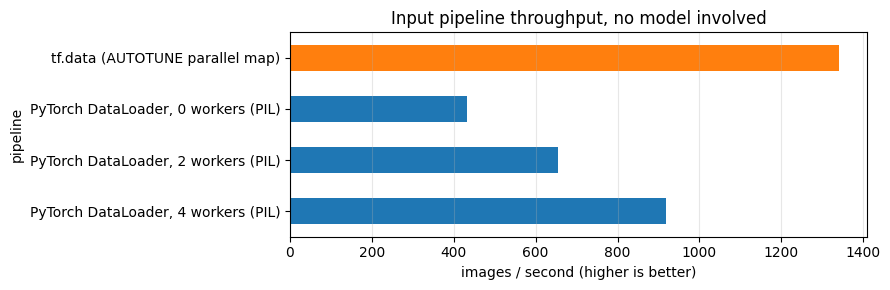

In [39]:
import traceback
try:
    AUTOTUNE = tf.data.AUTOTUNE

    def tf_load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        return tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True), label

    def make_tf_pipeline(repeat=False):
        ds = tf.data.Dataset.from_tensor_slices((np.array(bench_paths), bench_labels.astype("int32")))
        ds = ds.map(tf_load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
        return ds.repeat() if repeat else ds

    pt_transform = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])
    class BenchDS(torch.utils.data.Dataset):
        def __len__(self): return len(bench_paths)
        def __getitem__(self, i):
            return pt_transform(Image.open(bench_paths[i]).convert("RGB")), int(bench_labels[i])

    def make_pt_pipeline(workers):
        return torch.utils.data.DataLoader(BenchDS(), batch_size=BATCH, shuffle=False, num_workers=workers,
                                           pin_memory=True, persistent_workers=workers > 0)

    def time_epoch(iterable):
        t0 = time.perf_counter(); n = 0
        for x, _ in iterable:
            n += int(x.shape[0])
        return n / (time.perf_counter() - t0)

    PIPE_ROWS = []
    passes = 2 if QUICK else 4
    tf_ds = make_tf_pipeline()
    time_epoch(tf_ds)                                         # warm-up pass
    PIPE_ROWS.append({"pipeline": "tf.data (AUTOTUNE parallel map)", "img_per_s": float(np.median([time_epoch(tf_ds) for _ in range(passes)]))})
    for w in sorted({0, 2, min(4, N_CPU)}):
        dl = make_pt_pipeline(w)
        time_epoch(dl)                                        # warm-up pass (starts the workers)
        PIPE_ROWS.append({"pipeline": f"PyTorch DataLoader, {w} workers (PIL)", "img_per_s": float(np.median([time_epoch(dl) for _ in range(passes)]))})
        del dl; gc.collect()
    pipe_df = pd.DataFrame(PIPE_ROWS).set_index("pipeline")
    display(pipe_df.style.format({"img_per_s": "{:.0f}"}))
    pipe_df.to_csv(OUT_DIR / "bench_pipelines.csv")

    ax = pipe_df["img_per_s"].plot.barh(figsize=(9, 3), color=["tab:orange"] + ["tab:blue"] * (len(pipe_df) - 1))
    ax.set_xlabel("images / second (higher is better)"); ax.set_title("Input pipeline throughput, no model involved")
    ax.invert_yaxis(); ax.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()
except Exception as _e:
    print('[Section 4-6 cell 8] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


In [40]:
import traceback
try:
    # ---- 3. end-to-end: real pipeline + real training step, Model 2.
    #      Three variants: tf.function without XLA, TensorFlow with XLA (what Keras uses by default), PyTorch eager
    E2E_STEPS = 40 if QUICK else 150
    def infinite(loader):
        while True:
            for batch in loader:
                yield batch

    def e2e_tf(name, mode):
        with tf.device("/GPU:0"):
            step, keep = make_tf_train(name, mode)
            it = iter(make_tf_pipeline(repeat=True))
            for _ in range(20):
                out = step(*next(it))
            tf_sync(out)
            ms = []
            for _ in range(3):
                t0 = time.perf_counter()
                for _ in range(E2E_STEPS):
                    out = step(*next(it))
                tf_sync(out)
                ms.append((time.perf_counter() - t0) / E2E_STEPS * 1000)
        return float(np.median(ms))

    def e2e_pt(name, mode):
        step, keep = make_pt_train(name, mode)
        dl = make_pt_pipeline(min(4, N_CPU)); it = infinite(dl)
        def pt_batch():
            x, y = next(it)
            return step(x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True))
        for _ in range(20):
            pt_batch()
        torch.cuda.synchronize()
        ms = []
        for _ in range(3):
            t0 = time.perf_counter()
            for _ in range(E2E_STEPS):
                pt_batch()
            torch.cuda.synchronize()
            ms.append((time.perf_counter() - t0) / E2E_STEPS * 1000)
        return float(np.median(ms))

    E2E_ROWS = []
    for name in ("M2",):
        for variant, fw, fn, mode, compute_tier in (("TensorFlow tf.function", "TensorFlow", e2e_tf, "default", TIERS[0][1]),
                                                     ("TensorFlow XLA (Keras default)", "TensorFlow", e2e_tf, "compiler", TIERS[1][1]),
                                                     ("PyTorch eager", "PyTorch", e2e_pt, "default", TIERS[0][1])):
            row = {"model": name, "variant": variant, "framework": fw, "compute_tier": compute_tier}
            try:
                row["ms_per_step"] = fn(name, mode)
            except Exception as e:
                row["error"] = f"{type(e).__name__}: {str(e)[:160]}"
            E2E_ROWS.append(row)
            cleanup()

    e2e_df = ensure_cols(pd.DataFrame(E2E_ROWS), ["model", "variant", "framework", "compute_tier", "ms_per_step", "error"])
    e2e_df.to_csv(OUT_DIR / "bench_end_to_end.csv", index=False)
    display(e2e_df)

    # bottleneck analysis: compare with the pipeline-only and compute-only numbers
    def _get(df, **q):
        d = df
        for k, v in q.items():
            d = d[d[k] == v]
        return d
    try:
        for _, r in e2e_df[e2e_df["error"].isna()].iterrows():
            pipe_key = ("tf.data (AUTOTUNE parallel map)" if r["framework"] == "TensorFlow"
                        else f"PyTorch DataLoader, {min(4, N_CPU)} workers (PIL)")
            comp_ms = float(_get(train_df, model=r["model"], framework=r["framework"], tier=r["compute_tier"])["ms_per_step"].iloc[0])
            pipe_ms = BATCH / float(pipe_df.loc[pipe_key, "img_per_s"]) * 1000
            bottleneck = "data pipeline" if pipe_ms > comp_ms else "GPU compute"
            print(f"{r['variant']:<32} compute-only {comp_ms:6.1f} ms | pipeline-only {pipe_ms:6.1f} ms | "
                  f"end-to-end {r['ms_per_step']:6.1f} ms/step  -> bottleneck: {bottleneck}")
    except Exception as e:
        print("Bottleneck summary unavailable:", e)
except Exception as _e:
    print('[Section 4-6 cell 9] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


,model,variant,framework,compute_tier,ms_per_step,error
0,M2,TensorFlow tf.function,TensorFlow,default (TF graph / PT eager),49.240931,NaN
1,M2,TensorFlow XLA (Keras default),TensorFlow,compiler (XLA / torch.compile),23.733325,NaN
2,M2,PyTorch eager,PyTorch,default (TF graph / PT eager),38.026213,NaN


TensorFlow tf.function           compute-only   49.4 ms | pipeline-only   23.8 ms | end-to-end   49.2 ms/step  -> bottleneck: GPU compute
TensorFlow XLA (Keras default)   compute-only   21.4 ms | pipeline-only   23.8 ms | end-to-end   23.7 ms/step  -> bottleneck: data pipeline
PyTorch eager                    compute-only   37.4 ms | pipeline-only   34.8 ms | end-to-end   38.0 ms/step  -> bottleneck: GPU compute


### 4.5 Inference: latency, throughput, cold start, CPU

Inference models use random weights (speed does not depend on the weights). All calls return the result **on the host** (a 5-number vector per image), so GPU-to-CPU copy is included for both frameworks.

* **Latency**: one call at a time, p50 / p95 / p99 over many calls (what a single user request feels like).
* **Throughput**: images per second for increasing batch sizes (what a batch job or busy server gets).
* **Cold start**: the first call after building the model, including tracing / compilation (matters for serverless or short-lived services).
* **CPU**: the same on the CPU only (edge or no-GPU deployment).

Models 1 and 3 are used: one dense-dominated, one convolution-dominated. Model 2 has the same inference compute as Model 1 (dropout is off).

In [41]:
import traceback
try:
    INF_MODELS     = ["M1", "M3"]
    BATCH_SIZES    = [1, 8, 32, 128, 512]
    INF_TIERS      = [("default", "default (TF graph / PT eager)"),
                      ("compiler", "compiler (XLA / torch.compile)"),
                      ("fp16", "fp16 mixed precision"),
                      ("best", "compiler + fp16 (best effort)")]
    TARGET_SECONDS = 1.0 if QUICK else 3.0     # time budget per measurement

    def measure_calls(call, fetch, kind):
        """kind='latency': per-call ms list (fetch after every call). kind='throughput': total seconds / n calls."""
        out = call(); fetch(out)                                    # warm-up for this shape
        t0 = time.perf_counter(); fetch(call()); one = max(time.perf_counter() - t0, 1e-5)
        n = int(np.clip(TARGET_SECONDS / one, 10, 400 if kind == "latency" else 300))
        for _ in range(min(n, 10)):
            fetch(call())
        if kind == "latency":
            lat = []
            for _ in range(n):
                t0 = time.perf_counter(); fetch(call()); lat.append((time.perf_counter() - t0) * 1000)
            return np.array(lat)
        t0 = time.perf_counter()
        for _ in range(n):
            out = call()
        fetch(out)
        return (time.perf_counter() - t0) / n                      # seconds per call

    def make_tf_infer(name, mode, device):
        keras.backend.clear_session()
        keras.mixed_precision.set_global_policy("mixed_float16" if mode in ("fp16", "best") else "float32")
        import contextlib
        scope = (lambda: tf.device("/CPU:0")) if device == "CPU" else (lambda: contextlib.nullcontext())   # GPU is TF's default
        with scope():
            model = build_tf(name)
            fn = tf.function(lambda x: model(x, training=False), jit_compile=(mode in ("compiler", "best")))
        def make_input(bs):
            with scope():
                return tf.random.uniform((bs, IMG_SIZE, IMG_SIZE, 3), 0, 255)
        def call_with(x):
            def call():
                with scope():
                    return fn(x)
            return call
        return make_input, call_with, (lambda out: out.numpy()), (model, fn)

    def make_pt_infer(name, mode, device):
        dev = torch.device("cuda" if device == "GPU" else "cpu")
        model = build_pt(name, dev).eval()
        fwd = torch.compile(model, backend=PT_COMPILE_BACKEND) if mode in ("compiler", "best") else model
        use_amp = (mode in ("fp16", "best") and dev.type == "cuda")
        def make_input(bs):
            return torch.rand(bs, 3, IMG_SIZE, IMG_SIZE, device=dev)
        def call_with(x):
            def call():
                with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                    return fwd(x)
            return call
        fetch = (lambda out: out.float().cpu().numpy())
        return make_input, call_with, fetch, (model, fwd)

    def bench_inference(framework, name, mode, device, batch_sizes):
        maker = make_tf_infer if framework == "TensorFlow" else make_pt_infer
        t_build = time.perf_counter()
        make_input, call_with, fetch, keep = maker(name, mode, device)
        rows, first_call = [], None
        for bs in batch_sizes:
            x = make_input(bs); call = call_with(x)
            if first_call is None:
                t0 = time.perf_counter(); fetch(call()); first_call = time.perf_counter() - t0   # cold start (includes compile)
            lat = measure_calls(call, fetch, "latency")
            sec = measure_calls(call, fetch, "throughput")
            rows.append({"framework": framework, "model": name, "tier": mode, "device": device, "batch": bs,
                         "lat_p50_ms": float(np.percentile(lat, 50)), "lat_p95_ms": float(np.percentile(lat, 95)),
                         "lat_p99_ms": float(np.percentile(lat, 99)), "img_per_s": bs / sec,
                         "first_call_s": first_call})
        return rows

    INF_ROWS = []
    for name in INF_MODELS:
        for mode, tier_label in INF_TIERS:
            for fw in ("TensorFlow", "PyTorch"):
                try:
                    rows = bench_inference(fw, name, mode, "GPU", BATCH_SIZES)
                    for r in rows: r["tier_label"] = tier_label
                    INF_ROWS += rows
                    r1 = rows[0]
                    print(f"{name} | {tier_label:<32} | {fw:<10} | bs=1 p50 {r1['lat_p50_ms']:6.2f} ms | "
                          f"bs={BATCH_SIZES[-1]} {rows[-1]['img_per_s']:8.0f} img/s | cold start {r1['first_call_s']:5.1f}s")
                except Exception as e:
                    INF_ROWS.append({"framework": fw, "model": name, "tier": mode, "tier_label": tier_label, "device": "GPU",
                                     "error": f"{type(e).__name__}: {str(e)[:160]}"})
                    print(f"{name} | {tier_label:<32} | {fw:<10} | FAILED: {type(e).__name__}: {str(e)[:120]}")
                cleanup()
    keras.mixed_precision.set_global_policy("float32")
except Exception as _e:
    print('[Section 4-6 cell 10] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


M1 | default (TF graph / PT eager)    | TensorFlow | bs=1 p50   1.57 ms | bs=512     6541 img/s | cold start   0.1s
M1 | default (TF graph / PT eager)    | PyTorch    | FAILED: OutOfMemoryError: CUDA out of memory. Tried to allocate 344.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 296.81 MiB is free. I
M1 | compiler (XLA / torch.compile)   | TensorFlow | bs=1 p50   1.41 ms | bs=512    10105 img/s | cold start   0.5s
M1 | compiler (XLA / torch.compile)   | PyTorch    | FAILED: RuntimeError: The size of tensor a (8) must match the size of tensor b (32) at non-singleton dimension 0
M1 | fp16 mixed precision             | TensorFlow | bs=1 p50   2.58 ms | bs=512    15066 img/s | cold start   0.1s
M1 | fp16 mixed precision             | PyTorch    | FAILED: OutOfMemoryError: CUDA out of memory. Tried to allocate 686.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 442.81 MiB is free. I
M1 | compiler + fp16 (best effort)    | TensorFlow | bs=1 p50   2.70 ms | bs=512    29

In [42]:
import traceback
try:
    # ---------------- CPU inference (default tier only) ----------------
    try:
        torch.set_num_threads(N_CPU)
    except Exception:
        pass
    for name in INF_MODELS:
        for fw in ("TensorFlow", "PyTorch"):
            try:
                rows = bench_inference(fw, name, "default", "CPU", [1, 32])
                for r in rows: r["tier_label"] = INF_TIERS[0][1]
                INF_ROWS += rows
                print(f"{name} | CPU | {fw:<10} | bs=1 p50 {rows[0]['lat_p50_ms']:7.2f} ms | bs=32 {rows[1]['img_per_s']:7.1f} img/s")
            except Exception as e:
                INF_ROWS.append({"framework": fw, "model": name, "tier": "default", "tier_label": INF_TIERS[0][1], "device": "CPU",
                                 "error": f"{type(e).__name__}: {str(e)[:160]}"})
                print(f"{name} | CPU | {fw:<10} | FAILED: {type(e).__name__}: {str(e)[:120]}")
            cleanup()

    inf_df = ensure_cols(pd.DataFrame(INF_ROWS), ["framework", "model", "tier", "tier_label", "device", "batch", "lat_p50_ms",
                                                  "lat_p95_ms", "lat_p99_ms", "img_per_s", "first_call_s", "error"])
    inf_df.to_csv(OUT_DIR / "bench_inference.csv", index=False)
    display(inf_df[inf_df["error"].notna()] if "error" in inf_df else "No failures.")
except Exception as _e:
    print('[Section 4-6 cell 11] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


M1 | CPU | TensorFlow | bs=1 p50   20.14 ms | bs=32   283.5 img/s
M1 | CPU | PyTorch    | bs=1 p50   10.85 ms | bs=32   152.8 img/s
M3 | CPU | TensorFlow | bs=1 p50    8.13 ms | bs=32   158.9 img/s
M3 | CPU | PyTorch    | bs=1 p50    8.98 ms | bs=32    75.3 img/s


,framework,model,tier,device,batch,lat_p50_ms,lat_p95_ms,lat_p99_ms,img_per_s,first_call_s,tier_label,error
5,PyTorch,M1,default,GPU,NaN,NaN,NaN,NaN,NaN,NaN,default (TF graph / PT eager),OutOfMemoryError: CUDA out of memory. Tried to...
11,PyTorch,M1,compiler,GPU,NaN,NaN,NaN,NaN,NaN,NaN,compiler (XLA / torch.compile),RuntimeError: The size of tensor a (8) must ma...
17,PyTorch,M1,fp16,GPU,NaN,NaN,NaN,NaN,NaN,NaN,fp16 mixed precision,OutOfMemoryError: CUDA out of memory. Tried to...
23,PyTorch,M1,best,GPU,NaN,NaN,NaN,NaN,NaN,NaN,compiler + fp16 (best effort),RuntimeError: The size of tensor a (8) must ma...
29,PyTorch,M3,default,GPU,NaN,NaN,NaN,NaN,NaN,NaN,default (TF graph / PT eager),OutOfMemoryError: CUDA out of memory. Tried to...
35,PyTorch,M3,compiler,GPU,NaN,NaN,NaN,NaN,NaN,NaN,compiler (XLA / torch.compile),RuntimeError: The size of tensor a (8) must ma...
41,PyTorch,M3,fp16,GPU,NaN,NaN,NaN,NaN,NaN,NaN,fp16 mixed precision,OutOfMemoryError: CUDA out of memory. Tried to...
47,PyTorch,M3,best,GPU,NaN,NaN,NaN,NaN,NaN,NaN,compiler + fp16 (best effort),RuntimeError: The size of tensor a (8) must ma...


In [43]:
import traceback
try:
    ok = inf_df[inf_df["error"].isna()] if "error" in inf_df else inf_df
    gpu = ok[ok.device == "GPU"]

    def inf_pair(df, value, batch, lower_is_better):
        d = df[df.batch == batch].pivot_table(index=["model", "tier_label"], columns="framework", values=value)
        if not {"TensorFlow", "PyTorch"} <= set(d.columns):
            return d
        d["TF / PT"] = d["TensorFlow"] / d["PyTorch"]
        d["better"] = d["TF / PT"].apply(lambda r: "n/a (one side missing)" if not np.isfinite(r) else
                                         "tie" if abs(r - 1) < TIE_THRESHOLD
                                         else ("TensorFlow" if (r < 1) == lower_is_better else "PyTorch"))
        return d

    print("GPU latency, batch 1, p50 in ms (lower is better):")
    display(inf_pair(gpu, "lat_p50_ms", 1, True).style.format({"TensorFlow": "{:.2f}", "PyTorch": "{:.2f}", "TF / PT": "{:.2f}"}))
    print("GPU latency, batch 1, p99 in ms (tail latency, lower is better):")
    display(inf_pair(gpu, "lat_p99_ms", 1, True).style.format({"TensorFlow": "{:.2f}", "PyTorch": "{:.2f}", "TF / PT": "{:.2f}"}))
    print(f"GPU throughput, batch {BATCH_SIZES[-1]}, images/s (higher is better):")
    display(inf_pair(gpu, "img_per_s", BATCH_SIZES[-1], False).style.format({"TensorFlow": "{:.0f}", "PyTorch": "{:.0f}", "TF / PT": "{:.2f}"}))
    print("Cold start = first call after building the model, seconds (lower is better):")
    display(inf_pair(gpu, "first_call_s", 1, True).style.format({"TensorFlow": "{:.1f}", "PyTorch": "{:.1f}", "TF / PT": "{:.2f}"}))
    cpu = ok[ok.device == "CPU"]
    if len(cpu):
        print("CPU latency, batch 1, p50 in ms (lower is better):")
        display(inf_pair(cpu, "lat_p50_ms", 1, True).style.format({"TensorFlow": "{:.2f}", "PyTorch": "{:.2f}", "TF / PT": "{:.2f}"}))
        print("CPU throughput, batch 32, images/s (higher is better):")
        display(inf_pair(cpu, "img_per_s", 32, False).style.format({"TensorFlow": "{:.1f}", "PyTorch": "{:.1f}", "TF / PT": "{:.2f}"}))
except Exception as _e:
    print('[Section 4-6 cell 12] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


GPU latency, batch 1, p50 in ms (lower is better):


GPU latency, batch 1, p99 in ms (tail latency, lower is better):


GPU throughput, batch 512, images/s (higher is better):


Cold start = first call after building the model, seconds (lower is better):


CPU latency, batch 1, p50 in ms (lower is better):


,framework,PyTorch,TensorFlow,TF / PT,better
model,tier_label,,,,
M1,default (TF graph / PT eager),10.85,20.14,1.86,PyTorch
M3,default (TF graph / PT eager),8.98,8.13,0.91,TensorFlow


CPU throughput, batch 32, images/s (higher is better):


,framework,PyTorch,TensorFlow,TF / PT,better
model,tier_label,,,,
M1,default (TF graph / PT eager),152.8,283.5,1.86,TensorFlow
M3,default (TF graph / PT eager),75.3,158.9,2.11,TensorFlow


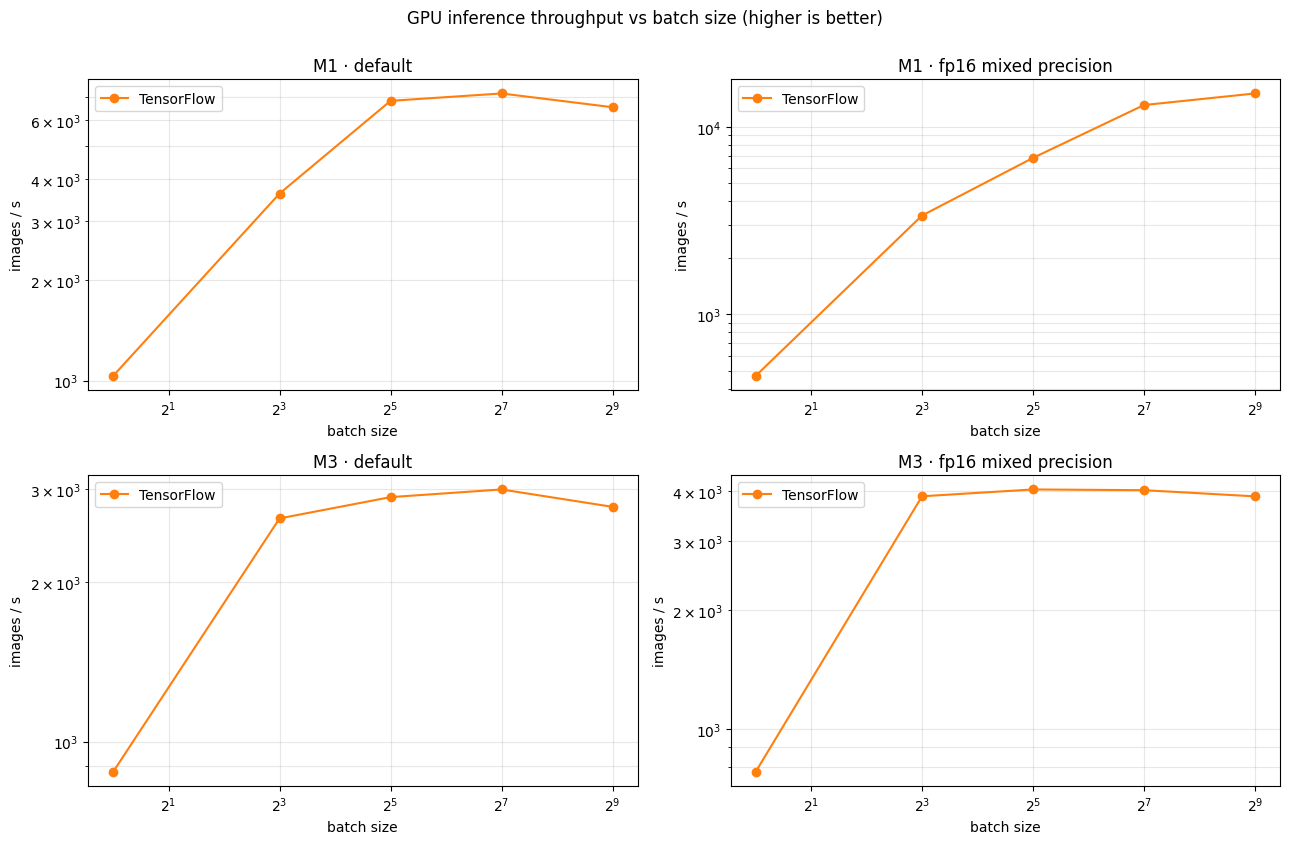

In [44]:
import traceback
try:
    # throughput vs batch size and latency vs batch size (GPU, default and fp16 tiers)
    tiers_to_plot = [INF_TIERS[0][1], INF_TIERS[2][1]]
    fig, axes = plt.subplots(len(INF_MODELS), len(tiers_to_plot), figsize=(13, 4.2 * len(INF_MODELS)), squeeze=False)
    for r, name in enumerate(INF_MODELS):
        for c, tier_label in enumerate(tiers_to_plot):
            ax = axes[r][c]
            for fw, col in (("TensorFlow", "tab:orange"), ("PyTorch", "tab:blue")):
                d = gpu[(gpu.model == name) & (gpu.tier_label == tier_label) & (gpu.framework == fw)].sort_values("batch")
                if len(d):
                    ax.plot(d.batch, d.img_per_s, "o-", color=col, label=fw)
            ax.set_xscale("log", base=2); ax.set_yscale("log")
            ax.set_title(f"{name} · {tier_label.split(' (')[0]}"); ax.set_xlabel("batch size"); ax.set_ylabel("images / s")
            ax.grid(alpha=.3, which="both"); ax.legend()
    plt.suptitle("GPU inference throughput vs batch size (higher is better)", y=1.0)
    plt.tight_layout(); plt.show()
except Exception as _e:
    print('[Section 4-6 cell 13] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


<a class="anchor" id="sec5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">5 · Is the Accuracy Difference Real?</p>

The test set has 11,250 images, so a difference of 0.2 to 0.4 percentage points is only 25 to 45 images. Two things decide whether such a gap means anything:

1. **Paired significance on the same test images** (McNemar's exact test) and a bootstrap confidence interval for the accuracy difference. This works with the single run above.
2. **Run-to-run variability**: GPU training is not bit-for-bit repeatable, so the same code with the same seed gives slightly different accuracies on every run. If results of other runs (for example the output of a copy of this notebook run with another `SEED`) are attached as inputs they are picked up automatically and the spread is shown. If the spread within one framework is as large as the gap between frameworks, the gap says nothing about the framework.

In [45]:
import traceback
try:
    from scipy.stats import binomtest
    from sklearn.metrics import accuracy_score

    KEYS = ["tensorflow_model1", "pytorch_model1", "tensorflow_model2", "pytorch_model2"]
    RUNS = {"this run": {k: RESULTS[k] for k in KEYS if k in RESULTS}}

    # optional: results of other runs (for example other seeds) attached to this notebook as inputs
    for f in sorted(glob.glob("/kaggle/input/**/results/*.pkl", recursive=True)):
        with open(f, "rb") as fh:
            res = pickle.load(fh)
        RUNS.setdefault(os.path.dirname(f), {})[res["key"]] = res
    RUNS = {d: r for d, r in RUNS.items() if all(k in r for k in KEYS)}
    print(f"Complete result sets: {len(RUNS)} (this run + {len(RUNS) - 1} attached from other runs)")
    for d, r in RUNS.items():
        print("  ", d, "| seed:", r[KEYS[0]].get("seed", "unknown"))

    def wilson(k, n, z=1.96):
        p = k / n; den = 1 + z * z / n
        centre = (p + z * z / (2 * n)) / den
        half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
        return centre - half, centre + half

    def paired_compare(a, b, n_boot=20000, seed=0):
        """McNemar exact test + bootstrap CI for accuracy(a) - accuracy(b) on the same images."""
        assert np.array_equal(a["y_true"], b["y_true"]), "Different test sets"
        ca = a["y_prob"].argmax(1) == a["y_true"]; cb = b["y_prob"].argmax(1) == b["y_true"]
        only_a, only_b = int((ca & ~cb).sum()), int((~ca & cb).sum())
        p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        n = len(ca); d = ca.astype(int) - cb.astype(int)
        probs = np.array([(d == 1).mean(), (d == -1).mean(), (d == 0).mean()])
        boot = np.random.default_rng(seed).multinomial(n, probs, size=n_boot)
        diff = (boot[:, 0] - boot[:, 1]) / n
        return {"acc A": ca.mean(), "acc B": cb.mean(), "A-B (pp)": 100 * (ca.mean() - cb.mean()),
                "95% CI low (pp)": 100 * np.percentile(diff, 2.5), "95% CI high (pp)": 100 * np.percentile(diff, 97.5),
                "only A right": only_a, "only B right": only_b, "McNemar p": p}

    PAIRS = [("TF M1 vs PT M1", "tensorflow_model1", "pytorch_model1"),
             ("TF M2 vs PT M2", "tensorflow_model2", "pytorch_model2"),
             ("TF M1 vs TF M2", "tensorflow_model1", "tensorflow_model2"),
             ("PT M1 vs PT M2", "pytorch_model1", "pytorch_model2")]
    STAT_ROWS = []
    for run, res in RUNS.items():
        seed = res[KEYS[0]].get("seed", "?")
        for name, ka, kb in PAIRS:
            STAT_ROWS.append({"run": run, "seed": seed,
                              "comparison": name, **paired_compare(res[ka], res[kb])})
    stat_df = pd.DataFrame(STAT_ROWS)
    if len(stat_df):
        display(stat_df.style.format({"acc A": "{:.4f}", "acc B": "{:.4f}", "A-B (pp)": "{:+.2f}", "95% CI low (pp)": "{:+.2f}",
                                      "95% CI high (pp)": "{:+.2f}", "McNemar p": "{:.4f}"}))
        print("pp = percentage points. 'A-B' > 0 means the first model is more accurate. A confidence interval that "
              "contains 0 (or p > 0.05) means the gap on this test set is not distinguishable from chance.")
        stat_df.to_csv(OUT_DIR / "stats_paired_tests.csv", index=False)
    else:
        print("No complete result set found: run Sections 1 and 2 first.")
except Exception as _e:
    print('[Section 4-6 cell 14] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


Complete result sets: 1 (this run + 0 attached from other runs)
   this run | seed: 42


,run,seed,comparison,acc A,acc B,A-B (pp),95% CI low (pp),95% CI high (pp),only A right,only B right,McNemar p
0,this run,42,TF M1 vs PT M1,0.9926,0.9876,+0.50,+0.29,+0.71,99,43,0.0000
1,this run,42,TF M2 vs PT M2,0.9882,0.9924,-0.43,-0.62,-0.24,38,86,0.0000
2,this run,42,TF M1 vs TF M2,0.9926,0.9882,+0.44,+0.24,+0.66,95,45,0.0000
3,this run,42,PT M1 vs PT M2,0.9876,0.9924,-0.48,-0.70,-0.26,54,108,0.0000


pp = percentage points. 'A-B' > 0 means the first model is more accurate. A confidence interval that contains 0 (or p > 0.05) means the gap on this test set is not distinguishable from chance.


In [46]:
import traceback
try:
    # accuracy with 95% confidence interval for every model of every run, and seed-to-seed spread when >= 2 runs exist
    acc_rows = []
    for run, res in RUNS.items():
        for k in KEYS:
            r = res[k]; n = len(r["y_true"]); correct = int((r["y_prob"].argmax(1) == r["y_true"]).sum())
            lo, hi = wilson(correct, n)
            acc_rows.append({"run": run, "seed": r.get("seed", "?"), "framework": r["framework"], "model": r["model"],
                             "test acc": correct / n, "ci low": lo, "ci high": hi})
    acc_df = pd.DataFrame(acc_rows)
    if len(acc_df):
        show = acc_df.copy(); show["95% CI (Wilson)"] = show.apply(lambda r: f"[{r['ci low']:.4f}, {r['ci high']:.4f}]", axis=1)
        display(show[["seed", "framework", "model", "test acc", "95% CI (Wilson)"]].style.format({"test acc": "{:.4f}"}))
        if len(RUNS) >= 2:
            agg = acc_df.groupby(["framework", "model"])["test acc"].agg(["mean", "std", "min", "max", "count"])
            display(agg.style.format({"mean": "{:.4f}", "std": "{:.4f}", "min": "{:.4f}", "max": "{:.4f}"}))
            fig, ax = plt.subplots(figsize=(8, 4))
            for i, ((fw, model), g) in enumerate(acc_df.groupby(["framework", "model"])):
                ax.scatter([i] * len(g), g["test acc"], s=60, color={"TensorFlow": "tab:orange", "PyTorch": "tab:blue"}[fw])
                ax.hlines(g["test acc"].mean(), i - .25, i + .25, color="k")
            ax.set_xticks(range(4)); ax.set_xticklabels([f"{fw[:2].upper()} {m}" for (fw, m), _ in acc_df.groupby(["framework", "model"])])
            ax.set_ylabel("test accuracy"); ax.set_title("Test accuracy per seed (black bar = mean)"); ax.grid(axis="y", alpha=.3)
            plt.tight_layout(); plt.show()
            print("If the spread within one framework is as large as the gap between frameworks, the framework is not the cause.")
        else:
            print("Only one run found, so run-to-run variability is not estimated here. To measure it, run a copy of this notebook with another SEED and attach its output as an input.")
except Exception as _e:
    print('[Section 4-6 cell 15] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


,seed,framework,model,test acc,95% CI (Wilson)
0,42,TensorFlow,Model 1,0.9926,"[0.9909, 0.9940]"
1,42,PyTorch,Model 1,0.9876,"[0.9854, 0.9895]"
2,42,TensorFlow,Model 2,0.9882,"[0.9860, 0.9900]"
3,42,PyTorch,Model 2,0.9924,"[0.9907, 0.9939]"


Only one run found, so run-to-run variability is not estimated here. To measure it, run a copy of this notebook with another SEED and attach its output as an input.


<a class="anchor" id="sec6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">6 · Final Scorecard</p>

Every row is computed from the tables above, nothing is typed in by hand. **TF advantage (x)** is above 1 when TensorFlow is better on that row (faster or smaller) and below 1 when PyTorch is. A row is a **tie** when the two frameworks differ by less than 5%. The note column says which comparisons are not perfectly symmetric.

In [47]:
import traceback
try:
    def pick(df, **q):
        d = df
        for k, v in q.items():
            d = d[d[k] == v]
        return d

    def score_row(dimension, metric, tf_val, pt_val, lower_is_better, note=""):
        if tf_val is None or pt_val is None or not np.isfinite(tf_val) or not np.isfinite(pt_val):
            return None
        ratio = tf_val / pt_val
        if abs(ratio - 1) < TIE_THRESHOLD:
            winner = "tie"
        else:
            winner = "TensorFlow" if (ratio < 1) == lower_is_better else "PyTorch"
        advantage = (1 / ratio) if lower_is_better else ratio          # > 1 always means TensorFlow is better
        return {"dimension": dimension, "metric": metric, "TensorFlow": tf_val, "PyTorch": pt_val,
                "TF advantage (x)": advantage, "better": winner, "note": note}

    SC = []
    def add(*a, **k):
        r = score_row(*a, **k)
        if r: SC.append(r)

    def val(df, value, **q):
        if value not in df.columns:
            return None
        d = pick(df, **q)
        return float(d[value].iloc[0]) if len(d) else None

    T0, T1, T2, T3 = (t[1] for t in TIERS)
    _compiler_note = f"XLA compiles the optimiser too; PyTorch compile backend here: {PT_COMPILE_BACKEND}"
    for m in MODELS:
        for tier, tag, note in ((T0, "default", "TF without XLA vs PyTorch eager"), (T1, "compiler", _compiler_note),
                                (T2, "fp16", ""), (T3, "best effort", "compiler + fp16 for both; " + _compiler_note)):
            add("Training speed", f"{m} step time, {tag} (ms)", val(train_df, "ms_per_step", model=m, tier=tier, framework="TensorFlow"),
                val(train_df, "ms_per_step", model=m, tier=tier, framework="PyTorch"), True, note)
    for m in MODELS:
        add("Training speed (out of the box)", f"{m} step time: Keras default (XLA) vs PyTorch eager (ms)",
            val(train_df, "ms_per_step", model=m, tier=T1, framework="TensorFlow"),
            val(train_df, "ms_per_step", model=m, tier=T0, framework="PyTorch"), True,
            "what each framework does without extra tuning: Keras compiles with XLA, PyTorch runs eager")
    for m in MODELS:
        add("Training memory", f"{m} peak GPU memory, default (MB)", val(train_df, "peak_mem_MB", model=m, tier=T0, framework="TensorFlow"),
            val(train_df, "peak_mem_MB", model=m, tier=T0, framework="PyTorch"), True, "different allocators")
        add("Cold start", f"{m} first training step, default (s)", val(train_df, "first_call_s", model=m, tier=T0, framework="TensorFlow"),
            val(train_df, "first_call_s", model=m, tier=T0, framework="PyTorch"), True)
    try:
        add("Data pipeline", "images/s, best loader of each", float(pipe_df.loc["tf.data (AUTOTUNE parallel map)", "img_per_s"]),
            float(pipe_df[pipe_df.index.str.startswith("PyTorch")]["img_per_s"].max()), False, "tf.data vs DataLoader (PIL), not the core framework")
        add("End-to-end training", "M2 ms/step with real data, no XLA", val(e2e_df, "ms_per_step", variant="TensorFlow tf.function"),
            val(e2e_df, "ms_per_step", variant="PyTorch eager"), True, "includes each framework's own loader")
        add("End-to-end training (out of the box)", "M2 ms/step with real data: Keras default (XLA) vs PyTorch eager",
            val(e2e_df, "ms_per_step", variant="TensorFlow XLA (Keras default)"), val(e2e_df, "ms_per_step", variant="PyTorch eager"), True,
            "includes each framework's own loader")
    except Exception:
        pass
    for m in INF_MODELS:
        for tier_label, tag in ((INF_TIERS[0][1], "default"), (INF_TIERS[1][1], "compiler"), (INF_TIERS[2][1], "fp16"),
                                (INF_TIERS[3][1], "best effort")):
            g = lambda v, fw, b, dev="GPU": val(inf_df, v, model=m, tier_label=tier_label, framework=fw, batch=b, device=dev)
            add("Inference latency", f"{m} GPU batch-1 p50, {tag} (ms)", g("lat_p50_ms", "TensorFlow", 1), g("lat_p50_ms", "PyTorch", 1), True)
            add("Inference latency", f"{m} GPU batch-1 p99, {tag} (ms)", g("lat_p99_ms", "TensorFlow", 1), g("lat_p99_ms", "PyTorch", 1), True)
            add("Inference throughput", f"{m} GPU batch-{BATCH_SIZES[-1]}, {tag} (img/s)", g("img_per_s", "TensorFlow", BATCH_SIZES[-1]),
                g("img_per_s", "PyTorch", BATCH_SIZES[-1]), False)
            add("Cold start", f"{m} first inference call, {tag} (s)", g("first_call_s", "TensorFlow", 1), g("first_call_s", "PyTorch", 1), True)
        gc_ = lambda v, fw, b: val(inf_df, v, model=m, tier_label=INF_TIERS[0][1], framework=fw, batch=b, device="CPU")
        add("CPU inference", f"{m} CPU batch-1 p50 (ms)", gc_("lat_p50_ms", "TensorFlow", 1), gc_("lat_p50_ms", "PyTorch", 1), True)
        add("CPU inference", f"{m} CPU batch-32 (img/s)", gc_("img_per_s", "TensorFlow", 32), gc_("img_per_s", "PyTorch", 32), False)

    # predictive performance: the verdict uses statistical significance (McNemar), not the raw gap
    try:
        cur = stat_df[stat_df["run"] == "this run"]
        for cmp_name, model_name in (("TF M1 vs PT M1", "Model 1"), ("TF M2 vs PT M2", "Model 2")):
            r = cur[cur["comparison"] == cmp_name].iloc[0]
            if r["McNemar p"] < 0.05:
                better = "TensorFlow" if r["A-B (pp)"] > 0 else "PyTorch"
            else:
                better = "tie"
            err_tf, err_pt = 1 - r["acc A"], 1 - r["acc B"]
            SC.append({"dimension": "Predictive performance", "metric": f"{model_name} test accuracy",
                       "TensorFlow": r["acc A"], "PyTorch": r["acc B"],
                       "TF advantage (x)": (err_pt / err_tf) if err_tf > 0 else float("nan"), "better": better,
                       "note": f"verdict by McNemar p={r['McNemar p']:.3f}; 95% CI of the difference "
                               f"[{r['95% CI low (pp)']:+.2f}, {r['95% CI high (pp)']:+.2f}] pp; one seed"})
    except Exception as e:
        print("Predictive rows skipped:", e)

    score_df = pd.DataFrame(SC)
    score_df.to_csv(OUT_DIR / "scorecard.csv", index=False)
    _sty = score_df.style.format({"TensorFlow": "{:.4g}", "PyTorch": "{:.4g}", "TF advantage (x)": "{:.2f}"})
    _color = lambda v: ("background-color:#fde2c8" if v == "TensorFlow" else "background-color:#cfe2f7" if v == "PyTorch"
                        else "background-color:#eeeeee" if v == "tie" else "")
    display((_sty.map if hasattr(_sty, "map") else _sty.applymap)(_color, subset=["better"]))

    score_summary = score_df.groupby(["dimension", "better"]).size().unstack(fill_value=0)
    for c in ("TensorFlow", "PyTorch", "tie"):
        if c not in score_summary: score_summary[c] = 0
    display(score_summary[["TensorFlow", "PyTorch", "tie"]])
except Exception as _e:
    print('[Section 4-6 cell 16] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


,dimension,metric,TensorFlow,PyTorch,TF advantage (x),better,note
0,Training speed,"M1 step time, default (ms)",38.36,27.44,0.72,PyTorch,TF without XLA vs PyTorch eager
1,Training speed,"M1 step time, compiler (ms)",18.69,28.97,1.55,TensorFlow,XLA compiles the optimiser too; PyTorch compile backend here: cudagraphs
2,Training speed,"M1 step time, fp16 (ms)",40.56,28.64,0.71,PyTorch,
3,Training speed,"M1 step time, best effort (ms)",12.94,30.4,2.35,TensorFlow,compiler + fp16 for both; XLA compiles the optimiser too; PyTorch compile backend here: cudagraphs
4,Training speed,"M2 step time, default (ms)",49.43,37.38,0.76,PyTorch,TF without XLA vs PyTorch eager
5,Training speed,"M2 step time, compiler (ms)",21.4,39.28,1.84,TensorFlow,XLA compiles the optimiser too; PyTorch compile backend here: cudagraphs
6,Training speed,"M2 step time, fp16 (ms)",51.84,39.02,0.75,PyTorch,
7,Training speed,"M2 step time, best effort (ms)",14.33,40.96,2.86,TensorFlow,compiler + fp16 for both; XLA compiles the optimiser too; PyTorch compile backend here: cudagraphs
8,Training speed,"M3 step time, default (ms)",55.94,33.46,0.60,PyTorch,TF without XLA vs PyTorch eager
9,Training speed,"M3 step time, compiler (ms)",27.23,34.01,1.25,TensorFlow,XLA compiles the optimiser too; PyTorch compile backend here: cudagraphs


better,TensorFlow,PyTorch,tie
dimension,,,
CPU inference,3,1,0
Cold start,0,3,0
Data pipeline,1,0,0
End-to-end training,0,1,0
End-to-end training (out of the box),1,0,0
Predictive performance,1,1,0
Training memory,0,3,0
Training speed,6,6,0
Training speed (out of the box),3,0,0


In [48]:
import traceback
try:
    # plain-language take-aways generated from the numbers
    print("Rows won per dimension (a row is a tie when the frameworks differ by < 5%):\n")
    for dim, g in score_df.groupby("dimension"):
        w = g["better"].value_counts().to_dict()
        med = g["TF advantage (x)"].median()
        print(f"- {dim}: TensorFlow {w.get('TensorFlow', 0)}, PyTorch {w.get('PyTorch', 0)}, tie {w.get('tie', 0)} "
              f"| median TensorFlow advantage {med:.2f}x")
    print("\nTensorFlow advantage > 1 means TensorFlow is better on that row (faster or smaller), < 1 means PyTorch is better.")
    print("Read the rows, not only the counts: the setting that matters for your use case (for example batch-1 GPU latency "
          "for an API, large-batch throughput for batch scoring, CPU for edge) decides which framework is 'better' for you.")
except Exception as _e:
    print('[Section 4-6 cell 17] FAILED and was skipped:', type(_e).__name__, _e)
    traceback.print_exc(limit=4)


Rows won per dimension (a row is a tie when the frameworks differ by < 5%):

- CPU inference: TensorFlow 3, PyTorch 1, tie 0 | median TensorFlow advantage 1.48x
- Cold start: TensorFlow 0, PyTorch 3, tie 0 | median TensorFlow advantage 0.02x
- Data pipeline: TensorFlow 1, PyTorch 0, tie 0 | median TensorFlow advantage 1.46x
- End-to-end training: TensorFlow 0, PyTorch 1, tie 0 | median TensorFlow advantage 0.77x
- End-to-end training (out of the box): TensorFlow 1, PyTorch 0, tie 0 | median TensorFlow advantage 1.60x
- Predictive performance: TensorFlow 1, PyTorch 1, tie 0 | median TensorFlow advantage 1.16x
- Training memory: TensorFlow 0, PyTorch 3, tie 0 | median TensorFlow advantage 0.27x
- Training speed: TensorFlow 6, PyTorch 6, tie 0 | median TensorFlow advantage 1.00x
- Training speed (out of the box): TensorFlow 3, PyTorch 0, tie 0 | median TensorFlow advantage 1.47x

TensorFlow advantage > 1 means TensorFlow is better on that row (faster or smaller), < 1 means PyTorch is bett

### Limitations (read before quoting any number)

* **One run, one seed.** Accuracy differences of a few tenths of a percent are within the epoch-to-epoch noise seen in the validation curves; use the significance tests in Section 5, and re-run with other seeds for stronger claims.
* **One GPU model and one software stack.** Results are for a Tesla T4 with the TensorFlow, Keras and PyTorch versions printed in Section 4.1. Other GPUs and library versions can change the ranking.
* **Small, dense-dominated models.** Models 1 and 2 spend most of their compute in one large dense layer. Model 3 (conv-heavy, benchmark only) checks whether the speed conclusions carry over; accuracy was not trained for it.
* **Compiler tiers are not perfectly symmetric.** XLA compiles the whole training step including the optimiser; `torch.compile` compiles the model's forward and backward while Adam stays eager. If Triton is unavailable the PyTorch tier uses the `cudagraphs` backend, which does not fuse kernels, so that row says little about what `torch.compile` can do on a fully set-up machine.
* **Keras uses XLA by default, PyTorch runs eager by default.** Both comparisons are reported: like for like (no XLA vs eager) and out of the box (XLA vs eager).
* **Each framework ran on its own T4** during the benchmarks. The two GPUs are the same model, but small card-to-card differences are not controlled for.
* **Input pipelines differ by design.** `tf.data` and the PyTorch `DataLoader` are each framework's native loader, which is what a user would use; Section 4.4 shows how much of end-to-end speed they explain.
* **Inference uses random weights** (speed does not depend on weights); the latency numbers include the copy of the result to the host for both frameworks.
* **Memory numbers come from each framework's own allocator** and are the steady-state peak after warm-up, so they are comparable in order of magnitude rather than byte for byte.